In [1]:
import sys
print("Версия Python:", sys.version)

Версия Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [2]:
!git clone https://github.com/pmenshih/tgo-course.git

Cloning into 'tgo-course'...
remote: Enumerating objects: 233, done.
remote: Counting objects: 100% (233/233), done.
remote: Compressing objects: 100% (165/165), done.
remote: Total 233 (delta 71), reused 196 (delta 36), pack-reused 0 (from 0)
Receiving objects: 100% (233/233), 5.70 MiB | 9.87 MiB/s, done.
Resolving deltas: 100% (71/71), done.


In [3]:
%cd /content/tgo-course
!ls

/content/tgo-course
 assignments   lab04	   pt01		      Курсовая.md
 cases	       lab05	   pt02		     'Профессиональный трек.md'
 demos	       lab06	   pytest.ini	     'Регламент лабораторных работ.md'
 lab01	       lab07	   README.md
 lab02	       lectures    requirements.txt
 lab03	       part-time   tests


In [4]:
!ls -la pt01
!ls -la pt01/artifacts
!ls -la tests/data/pt01
!ls -la tests/test_pt01.py

total 12
drwxr-xr-x  2 root root 4096 Nov 25 03:05 .
drwxr-xr-x 19 root root 4096 Nov 25 03:05 ..
-rw-r--r--  1 root root  757 Nov 25 03:05 run.py
ls: cannot access 'pt01/artifacts': No such file or directory
total 12
drwxr-xr-x 2 root root 4096 Nov 25 03:05 .
drwxr-xr-x 7 root root 4096 Nov 25 03:05 ..
-rw-r--r-- 1 root root  174 Nov 25 03:05 top20.json
-rw-r--r-- 1 root root 4939 Nov 25 03:05 tests/test_pt01.py


Скачивание текста «Война и мир».

In [5]:
from pathlib import Path
from urllib.request import urlretrieve
# Ссылка на корпус из методички
CORPUS_URL = (
    "https://raw.githubusercontent.com/nevmenandr/"
    "word2vec-russian-novels/master/books_before/WarAndPeace.txt"
)
# Пути к файлам первой лабораторной
LAB_DIR = Path("/content/tgo-course/pt01")
CORPUS = LAB_DIR / "corpus.txt"
ARTIFACTS = LAB_DIR / "artifacts"
# Создание папки для результатов
ARTIFACTS.mkdir(exist_ok=True)
# Скачивание корпуса
if not CORPUS.exists():
    urlretrieve(CORPUS_URL, CORPUS)
print("Корпус успешно скачан")
print("Путь к файлу:", CORPUS)
print("Размер файла в байтах:", CORPUS.stat().st_size)

Корпус успешно скачан
Путь к файлу: /content/tgo-course/pt01/corpus.txt
Размер файла в байтах: 5161320


Задание 1. Корпус и слова.

In [6]:
import re
from collections import Counter
# Чтение текста романа
text = CORPUS.read_text(encoding="utf-8")
# Приведение текста к нижнему регистру
text = text.lower().replace("ё", "е")
# Выделение слов по регулярному выражению
words = re.findall(r"[а-я]+(?:-[а-я]+)*", text)
# Разделение корпуса на 90% и 10%
split_index = int(len(words) * 0.9)
train_words = words[:split_index]
val_words = words[split_index:]
# Подсчёт частоты слов всего корпуса
word_counts = Counter(words)
# Размер словаря
vocab_size = len(word_counts)
# Двадцать самых частых слов
top20 = word_counts.most_common(20)
# Вывод результатов
print("Всего слов:", len(words))
print("Обучающая выборка:", len(train_words))
print("Проверочная выборка:", len(val_words))
print("Размер словаря:", vocab_size)

print("\n20 самых частых слов:")
for i, (word, count) in enumerate(top20, 1):
    print(f"{i:2}. {word:15} {count}")

Всего слов: 433082
Обучающая выборка: 389773
Проверочная выборка: 43309
Размер словаря: 48117

20 самых частых слов:
 1. и               21085
 2. в               10870
 3. не              8520
 4. что             7600
 5. он              7395
 6. на              6665
 7. с               5861
 8. как             4011
 9. его             3895
10. к               3428
11. я               2854
12. она             2732
13. но              2725
14. все             2674
15. было            2501
16. это             2434
17. то              2261
18. сказал          2000
19. так             1954
20. о               1832


Задание 2. Счетчики и вероятности.

In [7]:
# Подсчёт частоты слов обучающей выборки
train_counts = Counter(train_words)
# Подсчёт частоты пар соседних слов
bigram_counts = Counter(
    zip(train_words, train_words[1:])
)
# Размер словаря обучающей выборки
train_vocab_size = len(train_counts)

print("Размер словаря всего корпуса:", vocab_size)
print("Размер обучающего словаря:", train_vocab_size)
print("Всего биграмм:", sum(bigram_counts.values()))
print("Уникальных биграмм:", len(bigram_counts))

print("\n10 самых частых биграмм:")

for i, ((w1, w2), count) in enumerate(
    bigram_counts.most_common(10), 1
):
    print(f"{i:2}. {w1} + {w2}: {count}")

Размер словаря всего корпуса: 48117
Размер обучающего словаря: 45309
Всего биграмм: 389772
Уникальных биграмм: 236820

10 самых частых биграмм:
 1. князь + андрей: 775
 2. что + он: 754
 3. и + не: 650
 4. то + что: 538
 5. сказал + он: 458
 6. и + в: 441
 7. он + не: 425
 8. как + будто: 403
 9. о + том: 368
10. потому + что: 339


Создание класса языковой модели.

In [8]:
import math
import random
from collections import Counter, defaultdict

class BigramModel:
    # Инициализация модели
    def __init__(self, alpha=0.01):
        self.alpha = alpha
    # Обучение модели
    def fit(self, words):
        self.word_counts = Counter(words)
        self.bigram_counts = Counter(zip(words, words[1:]))
        self.context_counts = Counter(words[:-1])

        self.vocab = sorted(self.word_counts)
        self.vocab_size = len(self.vocab)

        # Возможные продолжения каждого слова
        self.followers = defaultdict(Counter)

        for (v, w), count in self.bigram_counts.items():
            self.followers[v][w] = count

        return self

    # Вероятность со сглаживанием Лапласа
    def prob(self, v, w):
        pair_count = self.bigram_counts.get((v, w), 0)
        context_count = self.context_counts.get(v, 0)

        # Дополнительная категория для неизвестных слов
        V = self.vocab_size + 1

        return (pair_count + self.alpha) / (
            context_count + self.alpha * V
        )

    # Генерация текста с температурой
    def generate(self, start, length=30,
                 temperature=1.0, seed=42):

        if temperature <= 0:
            raise ValueError("Температура должна быть больше нуля")

        rng = random.Random(seed)
        result = [start]

        while len(result) < length:
            current = result[-1]
            candidates = self.followers.get(current)

            if not candidates:
                candidates = self.word_counts

            next_words = list(candidates)

            weights = [
                count ** (1 / temperature)
                for count in candidates.values()
            ]
            next_word = rng.choices(
                next_words, weights=weights, k=1
            )[0]

            result.append(next_word)

        return " ".join(result)

    # Логарифм правдоподобия текста
    def logprob(self, words):
        return sum(
            math.log(self.prob(v, w))
            for v, w in zip(words, words[1:])
        )

# Создание и обучение модели
model = BigramModel(alpha=0.01)
model.fit(train_words)

print("Модель успешно обучена")
print("Размер словаря:", model.vocab_size)
print("Коэффициент сглаживания:", model.alpha)
print("\nПримеры вероятностей:")
print("P(андрей | князь):",
      model.prob("князь", "андрей"))
print("P(он | что):",
      model.prob("что", "он"))
print("P(наполеон | князь):",
      model.prob("князь", "наполеон"))

Модель успешно обучена
Размер словаря: 45309
Коэффициент сглаживания: 0.01

Примеры вероятностей:
P(андрей | князь): 0.4368468519249197
P(он | что): 0.10502848546475184
P(наполеон | князь): 5.63666084211713e-06


Задание 3. Генерация текста.

In [9]:
# Температуры для эксперимента
temperatures = [0.5, 1.0, 2.0]
# Стартовые слова
start_words = ["князь", "она"]
# Фиксируем seed для воспроизводимости
SEED = 42
# Список результатов генерации
generation = []
# Генерация текстов
for temperature in temperatures:
    for start in start_words:

        generated_text = model.generate(
            start=start,
            length=30,
            temperature=temperature,
            seed=SEED
        )
        # Сохранение результата
        generation.append({
            "temperature": temperature,
            "start": start,
            "text": generated_text
        })
        # Вывод результата
        print(f"Температура: {temperature}")
        print(f"Стартовое слово: {start}")
        print(generated_text)
        print("Количество слов:",
              len(generated_text.split()))
        print("-" * 60)

Температура: 0.5
Стартовое слово: князь
князь андрей не было он с тем чтобы не было в москве и с ним разговор и не мог удержаться чтобы в темноте ночи не говорили что он не был
Количество слов: 30
------------------------------------------------------------
Температура: 0.5
Стартовое слово: она
она была в ее и в нем несомненного друга и с ним и с ним разговор и не мог удержаться чтобы в темноте ночи не говорили что он не был
Количество слов: 30
------------------------------------------------------------
Температура: 1.0
Стартовое слово: князь
князь андрей не правда ли еще лаврушка кричал он очевидно не могу знать что он невольно этим штабным адъютантикам к ее ожидал найти кого-нибудь из виду цепи и что безухов
Количество слов: 30
------------------------------------------------------------
Температура: 1.0
Стартовое слово: она
она намерена была какая-то большая толпа людей сошли либо за то что никогда не успел придышаться в гостиной старая горничная попросите ко всей души ему проницат

Задание 4. Правдоподобие текста.

In [10]:
# Устанавливаем коэффициент сглаживания
model.alpha = 0.01
# Первые 12 слов проверочной выборки
sentence_words = val_words[:12]
# Создаём копию и перемешиваем слова
shuffled_words = sentence_words.copy()
rng = random.Random(SEED)
rng.shuffle(shuffled_words)
# Расчёт логарифма правдоподобия
logprob_sentence = model.logprob(sentence_words)
logprob_shuffled = model.logprob(shuffled_words)
# Подсчёт пар, отсутствующих в обучающей выборке
unseen_pairs = sum(
    1
    for v, w in zip(sentence_words, sentence_words[1:])
    if model.bigram_counts.get((v, w), 0) == 0
)
# Сохранение результатов для bigram.json
likelihood = {
    "sentence": " ".join(sentence_words),
    "shuffled": " ".join(shuffled_words),
    "alpha": model.alpha,
    "logprob_sentence": logprob_sentence,
    "logprob_shuffled": logprob_shuffled,
    "unseen_pairs_in_sentence": unseen_pairs
}
# Вывод результатов
print("Исходный текст:")
print(likelihood["sentence"])

print("\nПеремешанный текст:")
print(likelihood["shuffled"])

print("\nЛогарифм правдоподобия исходного текста:")
print(round(logprob_sentence, 4))

print("\nЛогарифм правдоподобия перемешанного текста:")
print(round(logprob_shuffled, 4))

print("\nКоличество ранее не встречавшихся пар:")
print(unseen_pairs)

print("\nИсходный текст правдоподобнее:")
print(logprob_sentence > logprob_shuffled)

Исходный текст:
это был георгий й степени на другой день были у фельдмаршала обед

Перемешанный текст:
день на георгий были у другой обед й степени это был фельдмаршала

Логарифм правдоподобия исходного текста:
-83.1429

Логарифм правдоподобия перемешанного текста:
-94.8913

Количество ранее не встречавшихся пар:
5

Исходный текст правдоподобнее:
True


Задание 5. Оценка модели — перплексия.

In [11]:
# Функция расчёта перплексии
def calculate_perplexity(model, words):
    log_probability = model.logprob(words)

    # Первое слово не оценивается
    N = len(words) - 1

    return math.exp(-log_probability / N)

# Коэффициенты сглаживания
alphas = [1, 0.1, 0.01]

# Словарь для сохранения результатов
perplexity = {}

print("Количество проверочных слов:",
      len(val_words))

print("Количество оцениваемых слов:",
      len(val_words) - 1)

print("\nРезультаты расчёта перплексии:")

for alpha in alphas:
    model.alpha = alpha

    ppl = calculate_perplexity(
        model, val_words
    )

    perplexity[str(alpha)] = ppl

    print(f"alpha = {alpha}: {ppl:.4f}")

# Определение лучшего коэффициента
best_alpha = min(
    perplexity,
    key=perplexity.get
)

print("\nЛучший коэффициент сглаживания:",
      best_alpha)

print("Минимальная перплексия:",
      round(perplexity[best_alpha], 4))

# Возвращаем исходный коэффициент
model.alpha = 0.01

Количество проверочных слов: 43309
Количество оцениваемых слов: 43308

Результаты расчёта перплексии:
alpha = 1: 15748.1131
alpha = 0.1: 7743.5441
alpha = 0.01: 5309.6357

Лучший коэффициент сглаживания: 0.01
Минимальная перплексия: 5309.6357


Создание файла bigram.json

In [12]:
import json
# Формирование результатов биграммной модели
bigram_results = {
    "corpus": CORPUS_URL,
    "words": len(words),
    "train_words": len(train_words),
    "val_words": len(val_words),
    "vocab_size": model.vocab_size,
    "top20": top20,
    "perplexity": perplexity,
    "likelihood": likelihood,
    "generation": generation
}
# Путь к файлу результатов
bigram_path = ARTIFACTS / "bigram.json"
# Сохранение результатов в JSON
with bigram_path.open("w", encoding="utf-8") as f:
    json.dump(
        bigram_results,
        f,
        ensure_ascii=False,
        indent=2
    )
# Проверка созданного файла
print("Файл bigram.json успешно создан")
print("Путь:", bigram_path)
print("Размер файла:", bigram_path.stat().st_size,
      "байт")
print("\nСодержимое файла:")
print(bigram_path.read_text(encoding="utf-8"))

Файл bigram.json успешно создан
Путь: /content/tgo-course/pt01/artifacts/bigram.json
Размер файла: 3930 байт

Содержимое файла:
{
  "corpus": "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt",
  "words": 433082,
  "train_words": 389773,
  "val_words": 43309,
  "vocab_size": 45309,
  "top20": [
    [
      "и",
      21085
    ],
    [
      "в",
      10870
    ],
    [
      "не",
      8520
    ],
    [
      "что",
      7600
    ],
    [
      "он",
      7395
    ],
    [
      "на",
      6665
    ],
    [
      "с",
      5861
    ],
    [
      "как",
      4011
    ],
    [
      "его",
      3895
    ],
    [
      "к",
      3428
    ],
    [
      "я",
      2854
    ],
    [
      "она",
      2732
    ],
    [
      "но",
      2725
    ],
    [
      "все",
      2674
    ],
    [
      "было",
      2501
    ],
    [
      "это",
      2434
    ],
    [
      "то",
      2261
    ],
    [
      "сказал",
      200

Задание 6. Свой BPE..

In [13]:
import time
# Маркер конца слова
END_WORD = "</w>"

# Функция объединения пары соседних символов
def merge_pair(symbols, pair):
    result = []
    i = 0

    while i < len(symbols):

        if (
            i < len(symbols) - 1
            and (symbols[i], symbols[i + 1]) == pair
        ):
            result.append(symbols[i] + symbols[i + 1])
            i += 2

        else:
            result.append(symbols[i])
            i += 1

    return result

# Функция обучения токенизатора BPE
def train_bpe(words, num_merges=1500, min_freq=5):

    # Частоты слов всего корпуса
    frequencies = Counter(words)

    # Разбиваем слова на символы
    # Редкие слова исключаем только из обучения BPE
    vocabulary = {
        word: list(word) + [END_WORD]
        for word, count in frequencies.items()
        if count >= min_freq
    }

    # Начальный словарь символов
    alphabet = set("".join(frequencies))
    alphabet.add(END_WORD)

    merges = []

    print("Уникальных слов в корпусе:",
          len(frequencies))

    print("Слов в обучающем словаре BPE:",
          len(vocabulary))

    print("Начальное количество символов:",
          len(alphabet))

    # Последовательное объединение пар
    for step in range(num_merges):

        pair_counts = Counter()

        # Подсчёт частот соседних пар
        for word, symbols in vocabulary.items():

            for pair in zip(symbols, symbols[1:]):
                pair_counts[pair] += frequencies[word]

        if not pair_counts:
            break

        # Выбираем наиболее частую пару
        best_pair = pair_counts.most_common(1)[0][0]

        # Сохраняем порядок слияний
        merges.append(best_pair)

        # Обновляем разбиение слов
        for word, symbols in vocabulary.items():
            vocabulary[word] = merge_pair(
                symbols, best_pair
            )

        # Добавляем новый токен в словарь
        alphabet.add(best_pair[0] + best_pair[1])

        # Отображение прогресса обучения
        if (step + 1) % 100 == 0:
            print(f"Выполнено слияний: "
                  f"{step + 1}/{num_merges}")

    return merges, alphabet

# Запоминаем время начала обучения
start_time = time.perf_counter()

# Обучаем BPE в полном режиме
merges, bpe_vocab = train_bpe(
    words,
    num_merges=1500,
    min_freq=5
)

# Рассчитываем время обучения
bpe_training_time = time.perf_counter() - start_time

print("\nОбучение BPE завершено")
print("Количество слияний:", len(merges))
print("Размер словаря BPE:", len(bpe_vocab))
print("Время обучения:",
      round(bpe_training_time, 2), "секунд")

print("\nПервые 10 слияний:")

for i, (a, b) in enumerate(merges[:10], 1):
    print(f"{i}. {a} + {b} = {a + b}")

Уникальных слов в корпусе: 48117
Слов в обучающем словаре BPE: 9002
Начальное количество символов: 34
Выполнено слияний: 100/1500
Выполнено слияний: 200/1500
Выполнено слияний: 300/1500
Выполнено слияний: 400/1500
Выполнено слияний: 500/1500
Выполнено слияний: 600/1500
Выполнено слияний: 700/1500
Выполнено слияний: 800/1500
Выполнено слияний: 900/1500
Выполнено слияний: 1000/1500
Выполнено слияний: 1100/1500
Выполнено слияний: 1200/1500
Выполнено слияний: 1300/1500
Выполнено слияний: 1400/1500
Выполнено слияний: 1500/1500

Обучение BPE завершено
Количество слияний: 1500
Размер словаря BPE: 1534
Время обучения: 62.67 секунд

Первые 10 слияний:
1. о + </w> = о</w>
2. и + </w> = и</w>
3. а + </w> = а</w>
4. е + </w> = е</w>
5. я + </w> = я</w>
6. с + т = ст
7. ь + </w> = ь</w>
8. а + л = ал
9. т + о = то
10. в + </w> = в</w>


Применение токенизатора и расчёт статистики.

In [14]:
# Создаём словарь рангов слияний
# Чем меньше ранг, тем раньше была объединена пара
merge_ranks = {
    pair: i for i, pair in enumerate(merges)
}
# Функция токенизации одного слова
def tokenize_bpe(word, ranks):

    symbols = list(word) + [END_WORD]

    while len(symbols) > 1:

        # Находим пары, присутствующие в списке слияний
        ranked_pairs = [
            (ranks[pair], i)
            for i, pair in enumerate(
                zip(symbols, symbols[1:])
            )
            if pair in ranks
        ]

        # Если больше нет доступных слияний
        if not ranked_pairs:
            break
        # Выбираем пару с наименьшим рангом
        _, i = min(ranked_pairs)
        # Объединяем выбранную пару
        symbols = (
            symbols[:i]
            + [symbols[i] + symbols[i + 1]]
            + symbols[i + 2:]
        )

    return symbols

# Частоты слов всего корпуса
frequencies = Counter(words)
# Токенизация всех уникальных слов
tokenized_words = {
    word: tokenize_bpe(word, merge_ranks)
    for word in frequencies
}
# Общее количество символов без маркеров конца слова
chars = sum(
    len(word) * count
    for word, count in frequencies.items()
)
# Общее количество токенов BPE
tokens_bpe = sum(
    len(tokenized_words[word]) * count
    for word, count in frequencies.items()
)
# Среднее количество токенов на слово
tokens_per_word = tokens_bpe / len(words)
# Коэффициент сжатия
compression_vs_chars = chars / tokens_bpe
# Статистика токенизации
bpe_stats = {
    "chars": chars,
    "words": len(words),
    "tokens_bpe": tokens_bpe,
    "tokens_per_word": tokens_per_word,
    "compression_vs_chars": compression_vs_chars
}

# Примеры токенизации
example_words = [
    "наполеон",
    "сказала",
    "неудовольствие",
    "андрей",
    "лошадь"
]

bpe_examples = {
    word: tokenize_bpe(word, merge_ranks)
    for word in example_words
}

# Вывод результатов
print("Статистика токенизации BPE:")
print("Количество символов:", chars)
print("Количество слов:", len(words))
print("Количество токенов BPE:", tokens_bpe)
print("Токенов на слово:",
      round(tokens_per_word, 4))
print("Коэффициент сжатия:",
      round(compression_vs_chars, 4))

print("\nПримеры токенизации:")

for word, tokens in bpe_examples.items():
    print(word, "->", tokens)

Статистика токенизации BPE:
Количество символов: 2245342
Количество слов: 433082
Количество токенов BPE: 836998
Токенов на слово: 1.9327
Коэффициент сжатия: 2.6826

Примеры токенизации:
наполеон -> ['наполеон</w>']
сказала -> ['сказала</w>']
неудовольствие -> ['не', 'удоволь', 'ствие</w>']
андрей -> ['андрей</w>']
лошадь -> ['лошадь</w>']


Создание файла bpe.json

In [15]:
# Формирование результатов токенизатора BPE
bpe_results = {
    "num_merges": len(merges),
    "vocab_size": len(bpe_vocab),
    "merges": merges,
    "stats": bpe_stats,
    "examples": bpe_examples
}

# Путь к файлу результатов
bpe_path = ARTIFACTS / "bpe.json"
# Сохранение результатов в JSON
with bpe_path.open("w", encoding="utf-8") as f:
    json.dump(
        bpe_results,
        f,
        ensure_ascii=False,
        indent=2
    )

# Проверка созданного файла
print("Файл bpe.json успешно создан")
print("Путь:", bpe_path)
print("Размер файла:", bpe_path.stat().st_size,
      "байт")

print("\nКоличество сохранённых слияний:",
      len(merges))

print("\nСтатистика:")
print(json.dumps(
    bpe_stats,
    ensure_ascii=False,
    indent=2
))

print("\nПримеры токенизации:")
print(json.dumps(
    bpe_examples,
    ensure_ascii=False,
    indent=2
))

# Проверка наличия обоих файлов
print("\nФайлы в папке artifacts:")

for path in sorted(ARTIFACTS.iterdir()):
    print(path.name, "-", path.stat().st_size, "байт")

Файл bpe.json успешно создан
Путь: /content/tgo-course/pt01/artifacts/bpe.json
Размер файла: 63624 байт

Количество сохранённых слияний: 1500

Статистика:
{
  "chars": 2245342,
  "words": 433082,
  "tokens_bpe": 836998,
  "tokens_per_word": 1.9326547859296854,
  "compression_vs_chars": 2.6826133395778724
}

Примеры токенизации:
{
  "наполеон": [
    "наполеон</w>"
  ],
  "сказала": [
    "сказала</w>"
  ],
  "неудовольствие": [
    "не",
    "удоволь",
    "ствие</w>"
  ],
  "андрей": [
    "андрей</w>"
  ],
  "лошадь": [
    "лошадь</w>"
  ]
}

Файлы в папке artifacts:
bigram.json - 3930 байт
bpe.json - 63624 байт


Создание самостоятельной программы.

In [17]:
import inspect
import textwrap

# Импорты и настройки самостоятельной программы
header = '''
"""Лабораторная работа №1. Заочное отделение.
Языковая модель из счётчиков и свой токенизатор.
"""

import argparse
import json
import math
import random
import re
import time

from pathlib import Path
from urllib.request import urlretrieve
from collections import Counter, defaultdict

HERE = Path(__file__).resolve().parent
ARTIFACTS = HERE / "artifacts"
CORPUS = HERE / "corpus.txt"

CORPUS_URL = (
    "https://raw.githubusercontent.com/nevmenandr/"
    "word2vec-russian-novels/master/books_before/WarAndPeace.txt"
)

END_WORD = "</w>"
SEED = 42
'''

# Получаем исходный код ранее созданных функций
components = [
    BigramModel,
    calculate_perplexity,
    merge_pair,
    train_bpe,
    tokenize_bpe
]

# Получаем исходный код из истории ячеек Colab
import ast

source_parts = {}

for cell_number in [8, 11, 13, 14]:
    source = In[cell_number]
    tree = ast.parse(source)

    for node in tree.body:
        if isinstance(node, (ast.ClassDef, ast.FunctionDef)):
            source_parts[node.name] = ast.get_source_segment(
                source, node
            )

# Собираем ранее разработанный класс и функции
functions_code = "\n\n".join(
    source_parts[component.__name__]
    for component in components
)

# Основная функция программы
main_code = '''

def main():
    parser = argparse.ArgumentParser()

    parser.add_argument(
        "--fast",
        action="store_true",
        help="Быстрый режим для CI"
    )

    args = parser.parse_args()
    ARTIFACTS.mkdir(exist_ok=True)

    # Задание 1. Корпус и слова
    if not CORPUS.exists():
        urlretrieve(CORPUS_URL, CORPUS)

    text = CORPUS.read_text(encoding="utf-8")
    text = text.lower().replace("ё", "е")

    words = re.findall(r"[а-я]+(?:-[а-я]+)*", text)

    split_index = int(len(words) * 0.9)

    train_words = words[:split_index]
    val_words = words[split_index:]

    frequencies = Counter(words)
    top20 = frequencies.most_common(20)

    # Задание 2. Обучение биграммной модели
    model = BigramModel(alpha=0.01)
    model.fit(train_words)

    # Задание 3. Генерация текста
    generation = []

    for temperature in [0.5, 1.0, 2.0]:
        for start in ["князь", "она"]:

            generated_text = model.generate(
                start=start,
                length=30,
                temperature=temperature,
                seed=SEED
            )

            generation.append({
                "temperature": temperature,
                "start": start,
                "text": generated_text
            })

    # Задание 4. Правдоподобие текста
    sentence_words = val_words[:12]
    shuffled_words = sentence_words.copy()

    rng = random.Random(SEED)
    rng.shuffle(shuffled_words)

    likelihood = {
        "sentence": " ".join(sentence_words),
        "shuffled": " ".join(shuffled_words),
        "alpha": model.alpha,
        "logprob_sentence": model.logprob(sentence_words),
        "logprob_shuffled": model.logprob(shuffled_words),
        "unseen_pairs_in_sentence": sum(
            1
            for v, w in zip(
                sentence_words, sentence_words[1:]
            )
            if model.bigram_counts.get((v, w), 0) == 0
        )
    }

    # Задание 5. Расчёт перплексии
    perplexity = {}

    for alpha in [1, 0.1, 0.01]:
        model.alpha = alpha

        perplexity[str(alpha)] = calculate_perplexity(
            model, val_words
        )

    model.alpha = 0.01

    bigram_results = {
        "corpus": CORPUS_URL,
        "words": len(words),
        "train_words": len(train_words),
        "val_words": len(val_words),
        "vocab_size": model.vocab_size,
        "top20": top20,
        "perplexity": perplexity,
        "likelihood": likelihood,
        "generation": generation
    }

    with (ARTIFACTS / "bigram.json").open(
        "w", encoding="utf-8"
    ) as f:
        json.dump(
            bigram_results, f,
            ensure_ascii=False, indent=2
        )

    # Задание 6. Обучение BPE
    num_merges = 200 if args.fast else 1500

    start_time = time.perf_counter()

    merges, bpe_vocab = train_bpe(
        words,
        num_merges=num_merges,
        min_freq=5
    )

    training_time = time.perf_counter() - start_time

    merge_ranks = {
        pair: i for i, pair in enumerate(merges)
    }

    tokenized_words = {
        word: tokenize_bpe(word, merge_ranks)
        for word in frequencies
    }

    chars = sum(
        len(word) * count
        for word, count in frequencies.items()
    )

    tokens_bpe = sum(
        len(tokenized_words[word]) * count
        for word, count in frequencies.items()
    )

    bpe_stats = {
        "chars": chars,
        "words": len(words),
        "tokens_bpe": tokens_bpe,
        "tokens_per_word": tokens_bpe / len(words),
        "compression_vs_chars": chars / tokens_bpe
    }

    example_words = [
        "наполеон",
        "сказала",
        "неудовольствие",
        "андрей",
        "лошадь"
    ]

    bpe_examples = {
        word: tokenize_bpe(word, merge_ranks)
        for word in example_words
    }

    bpe_results = {
        "num_merges": len(merges),
        "vocab_size": len(bpe_vocab),
        "merges": merges,
        "stats": bpe_stats,
        "examples": bpe_examples
    }

    with (ARTIFACTS / "bpe.json").open(
        "w", encoding="utf-8"
    ) as f:
        json.dump(
            bpe_results, f,
            ensure_ascii=False, indent=2
        )

    print("Лабораторная работа выполнена")
    print("Всего слов:", len(words))
    print("Перплексия:", perplexity)
    print("Количество слияний:", len(merges))
    print("Размер словаря BPE:", len(bpe_vocab))
    print("Время обучения BPE:", round(training_time, 2))
    print("Статистика BPE:", bpe_stats)
    print("Результаты сохранены в:", ARTIFACTS)


if __name__ == "__main__":
    main()
'''

# Объединяем весь программный код
full_code = header + "\n\n" + functions_code + "\n\n" + main_code

# Проверяем синтаксис перед сохранением
compile(full_code, "run.py", "exec")

# Записываем готовую программу
run_path = LAB_DIR / "run.py"

run_path.write_text(full_code, encoding="utf-8")

print("Файл run.py успешно создан")
print("Синтаксис проверен")
print("Путь:", run_path)
print("Размер файла:", run_path.stat().st_size, "байт")
print("Количество строк:", len(full_code.splitlines()))

Файл run.py успешно создан
Синтаксис проверен
Путь: /content/tgo-course/pt01/run.py
Размер файла: 11148 байт
Количество строк: 409


Проверка быстрого режима и автоматические тесты.

In [18]:
!python pt01/run.py --fast && python -m pytest tests/test_pt01.py -v

Уникальных слов в корпусе: 48117
Слов в обучающем словаре BPE: 9002
Начальное количество символов: 34
Выполнено слияний: 100/200
Выполнено слияний: 200/200
Лабораторная работа выполнена
Всего слов: 433082
Перплексия: {'1': 15748.113108406847, '0.1': 7743.54408984009, '0.01': 5309.635735733735}
Количество слияний: 200
Размер словаря BPE: 234
Время обучения BPE: 9.93
Статистика BPE: {'chars': 2245342, 'words': 433082, 'tokens_bpe': 1363489, 'tokens_per_word': 3.1483391136089702, 'compression_vs_chars': 1.6467620934235627}
Результаты сохранены в: /content/tgo-course/pt01/artifacts
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/tgo-course
configfile: pytest.ini
plugins: anyio-4.15.1, langsmith-0.14.12, platformdirs-4.13.5, typeguard-4.6.0
collected 8 items                                                              

tests/test_pt01.p

Проверка полного режима.

In [19]:
!python pt01/run.py && python -m pytest tests/test_pt01.py -v

Уникальных слов в корпусе: 48117
Слов в обучающем словаре BPE: 9002
Начальное количество символов: 34
Выполнено слияний: 100/1500
Выполнено слияний: 200/1500
Выполнено слияний: 300/1500
Выполнено слияний: 400/1500
Выполнено слияний: 500/1500
Выполнено слияний: 600/1500
Выполнено слияний: 700/1500
Выполнено слияний: 800/1500
Выполнено слияний: 900/1500
Выполнено слияний: 1000/1500
Выполнено слияний: 1100/1500
Выполнено слияний: 1200/1500
Выполнено слияний: 1300/1500
Выполнено слияний: 1400/1500
Выполнено слияний: 1500/1500
Лабораторная работа выполнена
Всего слов: 433082
Перплексия: {'1': 15748.113108406847, '0.1': 7743.54408984009, '0.01': 5309.635735733735}
Количество слияний: 1500
Размер словаря BPE: 1534
Время обучения BPE: 63.37
Статистика BPE: {'chars': 2245342, 'words': 433082, 'tokens_bpe': 836998, 'tokens_per_word': 1.9326547859296854, 'compression_vs_chars': 2.6826133395778724}
Результаты сохранены в: /content/tgo-course/pt01/artifacts
============================= test sessio

Бонус №1. Триграммная языковая модель

Подсчёт триграмм.

In [20]:
# Подсчёт частоты троек соседних слов
trigram_counts = Counter(
    zip(
        train_words,
        train_words[1:],
        train_words[2:]
    )
)

# Подсчёт частоты контекстов из двух слов
trigram_context_counts = Counter(
    zip(
        train_words[:-2],
        train_words[1:-1]
    )
)

# Вывод общей статистики
print("Количество обучающих слов:",
      len(train_words))

print("Общее количество триграмм:",
      sum(trigram_counts.values()))

print("Количество уникальных триграмм:",
      len(trigram_counts))

print("Количество уникальных контекстов:",
      len(trigram_context_counts))

# Вывод наиболее частых триграмм
print("\n10 самых частых триграмм:")

for i, ((w1, w2, w3), count) in enumerate(
    trigram_counts.most_common(10), 1
):
    print(f"{i:2}. {w1} + {w2} + {w3}: {count}")

Количество обучающих слов: 389773
Общее количество триграмм: 389771
Количество уникальных триграмм: 353032
Количество уникальных контекстов: 236820

10 самых частых триграмм:
 1. о + том + что: 159
 2. в + то + время: 145
 3. то + время + как: 129
 4. для + того + чтобы: 116
 5. на + то + что: 111
 6. сказал + князь + андрей: 109
 7. так + же + как: 106
 8. несмотря + на + то: 102
 9. в + том + что: 96
10. то + что + он: 94


Создание триграммной модели с механизмом отката.

In [21]:
# Триграммная языковая модель с откатом
class TrigramModel:

    def __init__(self, bigram_model, discount=0.75):
        self.bigram = bigram_model
        self.discount = discount
    # Обучение триграммной модели
    def fit(self, words):

        self.trigram_counts = Counter(
            zip(words, words[1:], words[2:])
        )

        self.context_counts = Counter(
            zip(words[:-2], words[1:-1])
        )

        self.followers = defaultdict(Counter)

        for (u, v, w), count in self.trigram_counts.items():
            self.followers[(u, v)][w] = count

        # Кэш коэффициентов отката
        self.backoff_cache = {}

        return self
    # Вероятность следующего слова
    def prob(self, u, v, w):

        context = (u, v)
        # Если контекст неизвестен, используем биграмму
        if context not in self.context_counts:
            return self.bigram.prob(v, w)

        total = self.context_counts[context]
        count = self.trigram_counts.get((u, v, w), 0)
        # Если триграмма встречалась
        if count > 0:
            return (count - self.discount) / total
        # Если триграмма не встречалась
        followers = self.followers[context]

        cache_key = (context, self.bigram.alpha)

        if cache_key not in self.backoff_cache:

            reserved_mass = (
                self.discount * len(followers) / total
            )

            known_mass = sum(
                self.bigram.prob(v, token)
                for token in followers
            )

            self.backoff_cache[cache_key] = (
                reserved_mass / (1 - known_mass)
            )

        backoff_weight = self.backoff_cache[cache_key]

        return backoff_weight * self.bigram.prob(v, w)

    # Логарифм правдоподобия текста
    def logprob(self, words):

        return sum(
            math.log(self.prob(u, v, w))
            for u, v, w in zip(
                words, words[1:], words[2:]
            )
        )

# Создание и обучение модели
trigram_model = TrigramModel(
    bigram_model=model,
    discount=0.75
)

trigram_model.fit(train_words)

print("Триграммная модель успешно обучена")
print("Коэффициент дисконтирования:",
      trigram_model.discount)

print("Уникальных триграмм:",
      len(trigram_model.trigram_counts))

print("\nПример известной триграммы:")

print("Частота:",
      trigram_model.trigram_counts.get(
          ("о", "том", "что"), 0
      ))

print("P(что | о, том):",
      trigram_model.prob("о", "том", "что"))

print("\nПример редкого продолжения:")

print("Частота:",
      trigram_model.trigram_counts.get(
          ("о", "том", "наполеон"), 0
      ))

print("P(наполеон | о, том):",
      trigram_model.prob("о", "том", "наполеон"))

# Проверка нормировки вероятностей
probability_sum = sum(
    trigram_model.prob("о", "том", word)
    for word in model.vocab + ["<UNK>"]
)

print("\nСумма вероятностей:",
      round(probability_sum, 8))

Триграммная модель успешно обучена
Коэффициент дисконтирования: 0.75
Уникальных триграмм: 353032

Пример известной триграммы:
Частота: 159
P(что | о, том): 0.43002717391304346

Пример редкого продолжения:
Частота: 0
P(наполеон | о, том): 2.48981479939971e-06

Сумма вероятностей: 1.0


Сравнение перплексии биграммной и триграммной моделей.

In [22]:
# Одинаковый коэффициент сглаживания
model.alpha = 0.01

# Количество оцениваемых слов
N = len(val_words) - 2

# Логарифм правдоподобия биграммной модели
bigram_logprob = model.logprob(val_words[1:])

# Логарифм правдоподобия триграммной модели
trigram_logprob = trigram_model.logprob(val_words)

# Расчёт перплексии обеих моделей
bigram_ppl = math.exp(-bigram_logprob / N)
trigram_ppl = math.exp(-trigram_logprob / N)

# Относительное снижение перплексии
improvement = (
    (bigram_ppl - trigram_ppl)
    / bigram_ppl * 100
)

# Подсчёт известных триграмм
known_trigrams = sum(
    1
    for triple in zip(
        val_words,
        val_words[1:],
        val_words[2:]
    )
    if triple in trigram_model.trigram_counts
)

# Количество откатов на биграммную модель
backoff_count = N - known_trigrams

backoff_percent = backoff_count / N * 100

# Вывод результатов
print("Сравнение языковых моделей")
print("Количество оцениваемых слов:", N)

print("\nПерплексия биграммной модели:",
      round(bigram_ppl, 4))

print("Перплексия триграммной модели:",
      round(trigram_ppl, 4))

print("\nСнижение перплексии (%):",
      round(improvement, 2))

print("\nИзвестных триграмм:",
      known_trigrams)

print("Количество откатов на биграммы:",
      backoff_count)

print("Доля откатов (%):",
      round(backoff_percent, 2))

if trigram_ppl < bigram_ppl:
    print("\nТриграммная модель показала лучший результат")
elif trigram_ppl > bigram_ppl:
    print("\nБиграммная модель показала лучший результат")
else:
    print("\nМодели показали одинаковый результат")

Сравнение языковых моделей
Количество оцениваемых слов: 43307

Перплексия биграммной модели: 5310.2781
Перплексия триграммной модели: 4946.6562

Снижение перплексии (%): 6.85

Известных триграмм: 4947
Количество откатов на биграммы: 38360
Доля откатов (%): 88.58

Триграммная модель показала лучший результат


Сравнение генерации текста.

In [23]:
def generate_with_context(language_model, start,
                          length=30, temperature=1.0,
                          seed=42):

    rng = random.Random(seed)

    # Начальный контекст из двух слов
    result = start.split()
    # Словарь возможных продолжений
    candidates = model.vocab

    while len(result) < length:

        # Вероятности триграммной модели
        if isinstance(language_model, TrigramModel):

            u, v = result[-2:]

            probabilities = [
                language_model.prob(u, v, w)
                for w in candidates
            ]

        # Вероятности биграммной модели
        else:

            v = result[-1]

            probabilities = [
                language_model.prob(v, w)
                for w in candidates
            ]

        # Применение температуры
        weights = [
            p ** (1 / temperature)
            for p in probabilities
        ]

        # Случайный выбор следующего слова
        next_word = rng.choices(
            candidates,
            weights=weights,
            k=1
        )[0]

        result.append(next_word)

    return " ".join(result)

# Начальные контексты
start_contexts = [
    "князь андрей",
    "она была"
]

# Сохранение результатов эксперимента
trigram_generation = []

for start in start_contexts:

    bigram_text = generate_with_context(
        model,
        start=start,
        length=30,
        temperature=1.0,
        seed=42
    )

    trigram_text = generate_with_context(
        trigram_model,
        start=start,
        length=30,
        temperature=1.0,
        seed=42
    )

    trigram_generation.append({
        "start": start,
        "temperature": 1.0,
        "bigram": bigram_text,
        "trigram": trigram_text
    })

    print("Начальный контекст:", start)

    print("\nБиграммная модель:")
    print(bigram_text)
    print("Количество слов:",
          len(bigram_text.split()))

    print("\nТриграммная модель:")
    print(trigram_text)
    print("Количество слов:",
          len(trigram_text.split()))

    print("=" * 60)

Начальный контекст: князь андрей

Биграммная модель:
князь андрей подъехал бессилии излить завоевав рамами приноси трезвым возки нашествия бивуак забавы осыпаны бесполезной дружные предположениях перевалился за подтверждением смертной анисье случившегося пролетев лампада готовность ходишь крыльев воображении воспитана
Количество слов: 30

Триграммная модель:
князь андрей подошел вложите изнанкой зависящая рамами приноси трезвым возки нашествия бивуак забавы осыпаны бесполезной дружные предположениях перевалился за подтверждением рассылок алтарем сложного пролетев лампада готовность ходишь крыльев воображении воспитана
Количество слов: 30
Начальный контекст: она была

Биграммная модель:
она была постелена бесе измене завтра рано прописал трезвым возки нашествия бивуак забавы осыпаны бесполезной дружные предположениях перевалился за подтверждением смертной анисье случившегося пролетев лампада готовность ходишь крыльев воображении воспитана
Количество слов: 30

Триграммная модель:
она был

Дополнительная проверка генерации.

Небольшой эксперимент при температуре T = 0,5, чтобы проверить, улучшится ли связность текстов при уменьшении случайности.

In [24]:
# Дополнительный эксперимент с низкой температурой
for start in start_contexts:
    bigram_text = generate_with_context(
        model,
        start=start,
        length=30,
        temperature=0.5,
        seed=42
    )

    trigram_text = generate_with_context(
        trigram_model,
        start=start,
        length=30,
        temperature=0.5,
        seed=42
    )

    trigram_generation.append({
        "start": start,
        "temperature": 0.5,
        "bigram": bigram_text,
        "trigram": trigram_text
    })

    print("Начальный контекст:", start)
    print("Температура: 0.5")

    print("\nБиграммная модель:")
    print(bigram_text)

    print("\nТриграммная модель:")
    print(trigram_text)

    print("=" * 60)

Начальный контекст: князь андрей
Температура: 0.5

Биграммная модель:
князь андрей не было в котором он не только в отношении административном компан диву благороднее заперли работой и даже не нужно было что он как будто спрашивая не было быть

Триграммная модель:
князь андрей не видал его и он опять стал говорить с вами князь василий в которой он стоял на том чтобы в этом не виноват в этом доме господин генерал
Начальный контекст: она была
Температура: 0.5

Биграммная модель:
она была не было в котором он не только в отношении административном компан диву благороднее заперли работой и даже не нужно было что он как будто спрашивая не было быть

Триграммная модель:
она была права и не говорите мне про это было бы в него на вопрос о том что он не мог бы но усомнился в том чтобы не было в


Сохранение результатов первого бонуса.

In [25]:
# Бонус №1. Сохранение результатов
# Создаём отдельную папку для бонусных заданий
BONUS_DIR = LAB_DIR / "bonus"
BONUS_DIR.mkdir(exist_ok=True)
# Формирование результатов эксперимента
trigram_results = {
    "train_words": len(train_words),
    "val_words": len(val_words),
    "evaluated_words": len(val_words) - 2,

    "alpha": model.alpha,
    "discount": trigram_model.discount,
    "seed": SEED,

    "total_trigrams": sum(
        trigram_counts.values()
    ),

    "unique_trigrams": len(trigram_counts),

    "unique_contexts": len(
        trigram_context_counts
    ),

    "top10": trigram_counts.most_common(10),

    "perplexity": {
        "bigram": bigram_ppl,
        "trigram": trigram_ppl,
        "improvement_percent": improvement
    },

    "backoff": {
        "known_trigrams": known_trigrams,
        "backoff_count": backoff_count,
        "backoff_percent": backoff_percent
    },

    "generation": trigram_generation
}

# Путь к файлу
trigram_path = BONUS_DIR / "trigram.json"

# Сохранение результатов
with trigram_path.open("w", encoding="utf-8") as f:
    json.dump(
        trigram_results,
        f,
        ensure_ascii=False,
        indent=2
    )

# Проверка сохранения
print("Бонус №1 успешно сохранён")
print("Путь:", trigram_path)
print("Размер файла:", trigram_path.stat().st_size,
      "байт")

print("\nПерплексия:")
print(json.dumps(
    trigram_results["perplexity"],
    ensure_ascii=False,
    indent=2
))

print("\nКоличество пар сравнения генерации:",
      len(trigram_generation))

print("Общее количество сгенерированных текстов:",
      len(trigram_generation) * 2)

print("\nФайлы бонусных заданий:")

for path in sorted(BONUS_DIR.iterdir()):
    print(path.name)

Бонус №1 успешно сохранён
Путь: /content/tgo-course/pt01/bonus/trigram.json
Размер файла: 4997 байт

Перплексия:
{
  "bigram": 5310.278141329916,
  "trigram": 4946.656203992976,
  "improvement_percent": 6.847512082406181
}

Количество пар сравнения генерации: 4
Общее количество сгенерированных текстов: 8

Файлы бонусных заданий:
trigram.json


Бонус №2. Другой размер словаря BPE.

Обучение BPE на 5000 слияниях.

In [26]:
# Бонус №2. Исследование размера словаря BPE
# Запоминаем время начала обучения
bonus_bpe_start_time = time.perf_counter()
# Обучение BPE на 5000 слияниях
bonus_merges, bonus_bpe_vocab = train_bpe(
    words,
    num_merges=5000,
    min_freq=5
)
# Время обучения
bonus_bpe_training_time = (
    time.perf_counter() - bonus_bpe_start_time
)
# Получаем три варианта токенизатора
bpe_variants = {
    300: bonus_merges[:300],
    1500: bonus_merges[:1500],
    5000: bonus_merges[:5000]
}

print("\nОбучение BPE завершено")

print("Количество слияний:",
      len(bonus_merges))

print("Размер словаря BPE:",
      len(bonus_bpe_vocab))

print("Время обучения:",
      round(bonus_bpe_training_time, 2),
      "секунд")

print("\nПодготовленные варианты BPE:")

for num, variant in bpe_variants.items():
    print(f"{num} слияний: {len(variant)}")

# Проверяем воспроизводимость основного эксперимента
print("\nСовпадение с основным BPE на 1500 слияниях:")

print(bpe_variants[1500] == merges)

Уникальных слов в корпусе: 48117
Слов в обучающем словаре BPE: 9002
Начальное количество символов: 34
Выполнено слияний: 100/5000
Выполнено слияний: 200/5000
Выполнено слияний: 300/5000
Выполнено слияний: 400/5000
Выполнено слияний: 500/5000
Выполнено слияний: 600/5000
Выполнено слияний: 700/5000
Выполнено слияний: 800/5000
Выполнено слияний: 900/5000
Выполнено слияний: 1000/5000
Выполнено слияний: 1100/5000
Выполнено слияний: 1200/5000
Выполнено слияний: 1300/5000
Выполнено слияний: 1400/5000
Выполнено слияний: 1500/5000
Выполнено слияний: 1600/5000
Выполнено слияний: 1700/5000
Выполнено слияний: 1800/5000
Выполнено слияний: 1900/5000
Выполнено слияний: 2000/5000
Выполнено слияний: 2100/5000
Выполнено слияний: 2200/5000
Выполнено слияний: 2300/5000
Выполнено слияний: 2400/5000
Выполнено слияний: 2500/5000
Выполнено слияний: 2600/5000
Выполнено слияний: 2700/5000
Выполнено слияний: 2800/5000
Выполнено слияний: 2900/5000
Выполнено слияний: 3000/5000
Выполнено слияний: 3100/5000
Выполнен

Сравнение статистики трёх токенизаторов.

In [27]:
# Бонус №2. Сравнение статистики BPE

frequencies = Counter(words)

# Начальный словарь символов
initial_alphabet = set("".join(frequencies))
initial_alphabet.add(END_WORD)
# Количество символов в корпусе
total_chars = sum(
    len(word) * count
    for word, count in frequencies.items()
)
# Функция оценки токенизатора
def evaluate_bpe(variant_merges):

    ranks = {
        pair: i
        for i, pair in enumerate(variant_merges)
    }

    # Формирование словаря токенов
    vocabulary = initial_alphabet.copy()

    for a, b in variant_merges:
        vocabulary.add(a + b)

    # Токенизация уникальных слов
    tokenized = {
        word: tokenize_bpe(word, ranks)
        for word in frequencies
    }

    # Общее количество токенов
    total_tokens = sum(
        len(tokenized[word]) * count
        for word, count in frequencies.items()
    )

    # Количество словоупотреблений,
    # представленных одним токеном
    whole_words = sum(
        count
        for word, count in frequencies.items()
        if len(tokenized[word]) == 1
    )

    return {
        "num_merges": len(variant_merges),
        "vocab_size": len(vocabulary),
        "tokens_bpe": total_tokens,
        "tokens_per_word": total_tokens / len(words),
        "compression_vs_chars": total_chars / total_tokens,
        "whole_words": whole_words,
        "whole_words_percent": whole_words / len(words) * 100
    }
# Сохранение результатов сравнения
bpe_comparison = {}

for num, variant in bpe_variants.items():

    stats = evaluate_bpe(variant)

    bpe_comparison[num] = stats

    print(f"\nBPE: {num} слияний")
    print("Размер словаря:",
          stats["vocab_size"])

    print("Количество токенов:",
          stats["tokens_bpe"])

    print("Токенов на слово:",
          round(stats["tokens_per_word"], 4))

    print("Коэффициент сжатия:",
          round(stats["compression_vs_chars"], 4))

    print("Словоупотреблений одним токеном:",
          stats["whole_words"])

    print("Доля целых слов (%):",
          round(stats["whole_words_percent"], 2))

    print("-" * 50)

# Проверка совпадения с основным экспериментом
print("\nСовпадение статистики BPE на 1500 слияниях:")

print(
    bpe_comparison[1500]["tokens_bpe"]
    == bpe_stats["tokens_bpe"]
)


BPE: 300 слияний
Размер словаря: 334
Количество токенов: 1240622
Токенов на слово: 2.8646
Коэффициент сжатия: 1.8099
Словоупотреблений одним токеном: 147969
Доля целых слов (%): 34.17
--------------------------------------------------

BPE: 1500 слияний
Размер словаря: 1534
Количество токенов: 836998
Токенов на слово: 1.9327
Коэффициент сжатия: 2.6826
Словоупотреблений одним токеном: 242285
Доля целых слов (%): 55.94
--------------------------------------------------

BPE: 5000 слияний
Размер словаря: 5034
Количество токенов: 645192
Токенов на слово: 1.4898
Коэффициент сжатия: 3.4801
Словоупотреблений одним токеном: 316200
Доля целых слов (%): 73.01
--------------------------------------------------

Совпадение статистики BPE на 1500 слияниях:
True


Исследование разбиения частых и редких слов.

In [28]:
# Частоты слов корпуса
frequencies = Counter(words)
# Фиксируем seed для выбора примеров
rng = random.Random(SEED)
# Частые и знакомые нам слова
selected_words = [
    "и",
    "князь",
    "андрей",
    "наполеон",
    "сказала",
    "неудовольствие"
]
# Выбираем слова с разной частотой
frequency_ranges = [
    (5, 9),
    (2, 4),
    (1, 1)
]

for low, high in frequency_ranges:

    candidates = sorted(
        word
        for word, count in frequencies.items()
        if low <= count <= high
        and len(word) >= 8
        and word not in selected_words
    )

    # Выбираем два слова из каждой группы
    selected_words.extend(
        rng.sample(
            candidates,
            min(2, len(candidates))
        )
    )

# Ранги слияний для каждого варианта BPE
variant_ranks = {
    num: {
        pair: i
        for i, pair in enumerate(variant)
    }
    for num, variant in bpe_variants.items()
}

# Сохранение результатов сравнения
bpe_example_comparison = {}

for word in selected_words:

    print("\nСлово:", word)
    print("Частота в корпусе:", frequencies[word])
    print("Количество символов:", len(word))

    bpe_example_comparison[word] = {
        "frequency": frequencies[word],
        "length": len(word),
        "variants": {}
    }

    for num, ranks in variant_ranks.items():

        tokens = tokenize_bpe(word, ranks)

        bpe_example_comparison[word]["variants"][num] = {
            "tokens": tokens,
            "num_tokens": len(tokens)
        }

        print(f"\n{num} слияний:")
        print("Разбиение:", " | ".join(tokens))
        print("Количество токенов:", len(tokens))

    print("-" * 60)


Слово: и
Частота в корпусе: 21085
Количество символов: 1

300 слияний:
Разбиение: и</w>
Количество токенов: 1

1500 слияний:
Разбиение: и</w>
Количество токенов: 1

5000 слияний:
Разбиение: и</w>
Количество токенов: 1
------------------------------------------------------------

Слово: князь
Частота в корпусе: 1329
Количество символов: 5

300 слияний:
Разбиение: князь</w>
Количество токенов: 1

1500 слияний:
Разбиение: князь</w>
Количество токенов: 1

5000 слияний:
Разбиение: князь</w>
Количество токенов: 1
------------------------------------------------------------

Слово: андрей
Частота в корпусе: 794
Количество символов: 6

300 слияний:
Разбиение: андре | й</w>
Количество токенов: 2

1500 слияний:
Разбиение: андрей</w>
Количество токенов: 1

5000 слияний:
Разбиение: андрей</w>
Количество токенов: 1
------------------------------------------------------------

Слово: наполеон
Частота в корпусе: 304
Количество символов: 8

300 слияний:
Разбиение: на | по | ле | он</w>
Количество ток

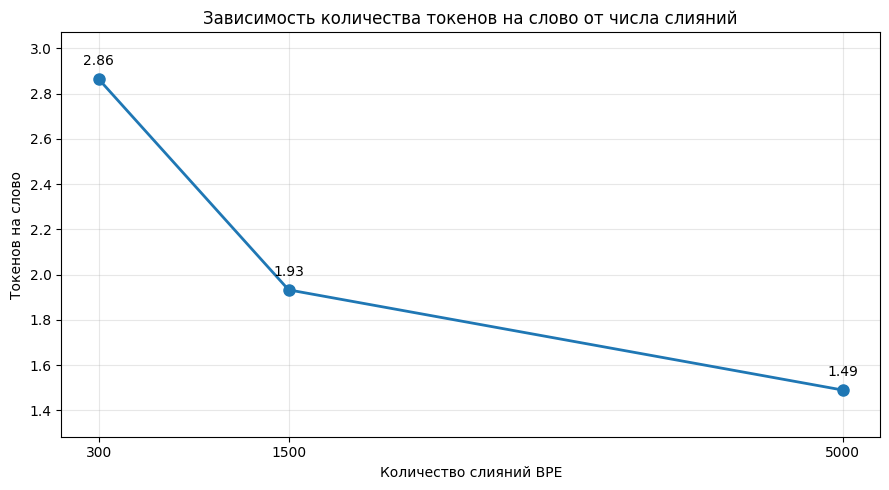

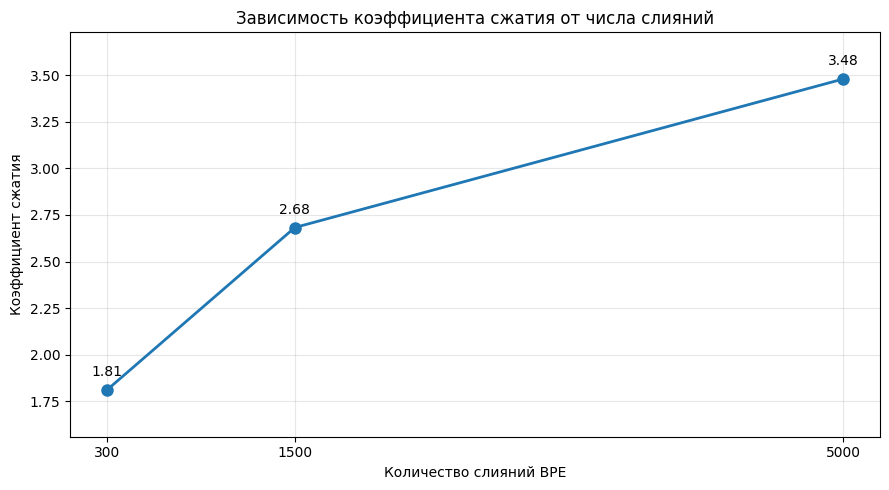

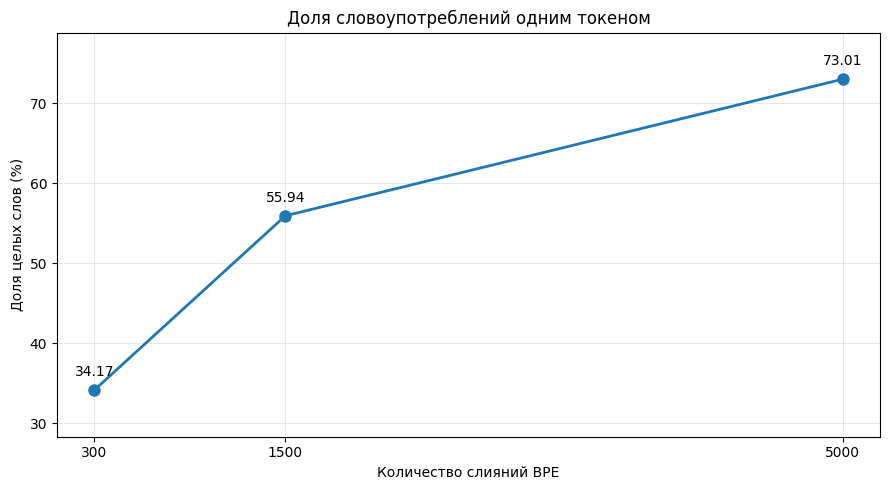

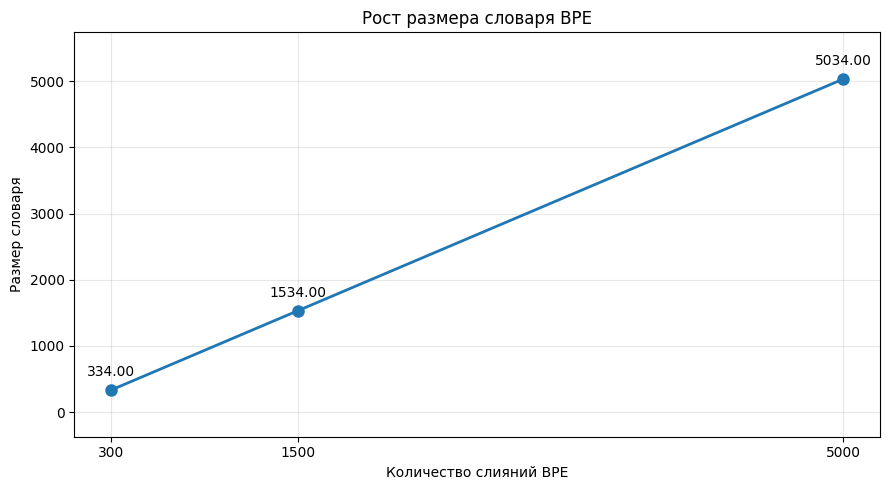

Все четыре графика успешно сохранены
Папка: /content/tgo-course/pt01/bonus


In [29]:
# Бонус №2. Визуализация результатов

import matplotlib.pyplot as plt

# Количество слияний
merge_numbers = sorted(bpe_comparison)
# Функция построения и сохранения графика
def plot_bpe_metric(metric, title, ylabel, filename):

    values = [
        bpe_comparison[num][metric]
        for num in merge_numbers
    ]

    plt.figure(figsize=(9, 5))

    plt.plot(
        merge_numbers,
        values,
        marker="o",
        linewidth=2,
        markersize=8
    )

    # Подписи значений
    for x, y in zip(merge_numbers, values):
        plt.annotate(
            f"{y:.2f}",
            (x, y),
            textcoords="offset points",
            xytext=(0, 10),
            ha="center"
        )

    plt.title(title)
    plt.xlabel("Количество слияний BPE")
    plt.ylabel(ylabel)
    plt.xticks(merge_numbers)
    plt.grid(alpha=0.3)
    plt.margins(y=0.15)
    plt.tight_layout()

    # Сохранение графика
    plt.savefig(
        BONUS_DIR / filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# График 1. Среднее количество токенов на слово
plot_bpe_metric(
    "tokens_per_word",
    "Зависимость количества токенов на слово от числа слияний",
    "Токенов на слово",
    "bpe_tokens_per_word.png"
)

# График 2. Коэффициент сжатия
plot_bpe_metric(
    "compression_vs_chars",
    "Зависимость коэффициента сжатия от числа слияний",
    "Коэффициент сжатия",
    "bpe_compression.png"
)

# График 3. Доля целых слов
plot_bpe_metric(
    "whole_words_percent",
    "Доля словоупотреблений одним токеном",
    "Доля целых слов (%)",
    "bpe_whole_words.png"
)

# График 4. Размер словаря
plot_bpe_metric(
    "vocab_size",
    "Рост размера словаря BPE",
    "Размер словаря",
    "bpe_vocab_size.png"
)

print("Все четыре графика успешно сохранены")
print("Папка:", BONUS_DIR)

In [30]:
# Бонус №2. Сохранение результатов эксперимента
bpe_bonus_results = {
    "corpus": CORPUS_URL,
    "total_words": len(words),
    "total_chars": total_chars,
    "min_freq": 5,
    "seed": SEED,

    "training_time_seconds": bonus_bpe_training_time,

    "comparison": bpe_comparison,

    "examples": bpe_example_comparison,

    "merges": bonus_merges,

    "reproducibility": {
        "merges_match": bpe_variants[1500] == merges,

        "statistics_match": (
            bpe_comparison[1500]["tokens_bpe"]
            == bpe_stats["tokens_bpe"]
        )
    }
}

# Путь к файлу результатов
bpe_bonus_path = BONUS_DIR / "bpe_comparison.json"

# Сохранение результатов
with bpe_bonus_path.open("w", encoding="utf-8") as f:
    json.dump(
        bpe_bonus_results,
        f,
        ensure_ascii=False,
        indent=2
    )

print("Бонус №2 успешно сохранён")
print("Путь:", bpe_bonus_path)
print("Размер файла:",
      bpe_bonus_path.stat().st_size, "байт")

print("\nКоличество вариантов BPE:",
      len(bpe_comparison))

print("Количество исследованных слов:",
      len(bpe_example_comparison))

print("Количество сохранённых слияний:",
      len(bonus_merges))

# Проверка сохранения графиков
print("\nКоличество сохранённых графиков:",
      len(list(BONUS_DIR.glob("*.png"))))

# Проверка файлов бонусных заданий
print("\nФайлы в папке bonus:")

for path in sorted(BONUS_DIR.iterdir()):
    print(path.name, "-", path.stat().st_size, "байт")

Бонус №2 успешно сохранён
Путь: /content/tgo-course/pt01/bonus/bpe_comparison.json
Размер файла: 232538 байт

Количество вариантов BPE: 3
Количество исследованных слов: 12
Количество сохранённых слияний: 5000

Количество сохранённых графиков: 4

Файлы в папке bonus:
bpe_comparison.json - 232538 байт
bpe_compression.png - 86415 байт
bpe_tokens_per_word.png - 86309 байт
bpe_vocab_size.png - 82167 байт
bpe_whole_words.png - 74560 байт
trigram.json - 4997 байт


Бонус №3. Наивный Байес на тех же счётчиках.

Загрузка второго корпуса.

Для эксперимента я выбрала роман Ф. М. Достоевского «Преступление и наказание». Его оригинальный текст находится в том же репозитории, откуда мы скачивали «Войну и мир».

In [31]:
from pathlib import Path
from urllib.request import urlretrieve

DOSTOEVSKY_URL = (
    "https://raw.githubusercontent.com/nevmenandr/"
    "word2vec-russian-novels/master/books_before/"
    "CrimeAndPunishment.txt"
)

# Сохраняем второй корпус отдельно от репозитория
DOSTOEVSKY_CORPUS = Path(
    "/content/corpus_dostoevsky.txt"
)

# Скачиваем текст, если файла ещё нет
if not DOSTOEVSKY_CORPUS.exists():
    urlretrieve(
        DOSTOEVSKY_URL,
        DOSTOEVSKY_CORPUS
    )

# Читаем оригинальные тексты обоих авторов
tolstoy_text = CORPUS.read_text(
    encoding="utf-8-sig"
)

dostoevsky_text = DOSTOEVSKY_CORPUS.read_text(
    encoding="utf-8-sig"
)

# Вывод результатов
print("Оба корпуса успешно загружены")

print("\nКорпус №1")
print("Автор: Л. Н. Толстой")
print("Произведение: Война и мир")
print("Размер файла:", CORPUS.stat().st_size,
      "байт")

print("\nКорпус №2")
print("Автор: Ф. М. Достоевский")
print("Произведение: Преступление и наказание")
print("Размер файла:",
      DOSTOEVSKY_CORPUS.stat().st_size,
      "байт")

print("\nНачало второго корпуса:")
print(dostoevsky_text[:500])

Оба корпуса успешно загружены

Корпус №1
Автор: Л. Н. Толстой
Произведение: Война и мир
Размер файла: 5161320 байт

Корпус №2
Автор: Ф. М. Достоевский
Произведение: Преступление и наказание
Размер файла: 1916380 байт

Начало второго корпуса:
ПРЕСТУПЛЕНИЕ И НАКАЗАНИЕ
РОМАН 
В ШЕСТИ ЧАСТЯХ С ЭПИЛОГОМ

ЧАСТЬ ПЕРВАЯ

I

В начале июля, в чрезвычайно жаркое время, под вечер, один молодой человек вышел из своей каморки, которую нанимал от жильцов в С - м переулке, на улицу и медленно, как бы в нерешимости, отправился к К - ну мосту.
Он благополучно избегнул встречи с своею хозяйкой на лестнице. Каморка его приходилась под самою кровлей высокого пятиэтажного дома и походила более на шкаф, чем на квартиру. Квартирная же хозяйка его, у которо


Предобработка текстов и разделение на выборки.

In [32]:
# Бонус №3. Предобработка текстов
import re
from collections import Counter
# Функция обработки текста
def prepare_sentences(text, min_words=5):

    # Разделение текста на предложения
    raw_sentences = re.split(r"[.!?…]+", text)

    sentences = []

    for sentence in raw_sentences:

        # Нормализация текста
        sentence = sentence.lower().replace("ё", "е")

        # Выделение русских слов
        tokens = re.findall(
            r"[а-я]+(?:-[а-я]+)*",
            sentence
        )

        # Исключение коротких предложений
        if len(tokens) >= min_words:
            sentences.append(tokens)

    return sentences


# Обработка произведений
tolstoy_sentences = prepare_sentences(
    tolstoy_text
)

dostoevsky_sentences = prepare_sentences(
    dostoevsky_text
)

# Разделение на обучение и проверку
def split_sentences(sentences):

    split_index = int(len(sentences) * 0.9)

    return (
        sentences[:split_index],
        sentences[split_index:]
    )

# Выборки Толстого
tolstoy_train, tolstoy_val = split_sentences(
    tolstoy_sentences
)

# Выборки Достоевского
dostoevsky_train, dostoevsky_val = split_sentences(
    dostoevsky_sentences
)

# Вывод статистики
def print_corpus_stats(author, sentences,
                       train, val):

    print("\nАвтор:", author)

    print("Всего предложений:",
          len(sentences))

    print("Обучающих предложений:",
          len(train))

    print("Проверочных предложений:",
          len(val))

    print("Слов в обучающей выборке:",
          sum(len(s) for s in train))

    print("Слов в проверочной выборке:",
          sum(len(s) for s in val))

    print("Доля проверочных предложений (%):",
          round(len(val) / len(sentences) * 100, 2))

    print("\nПример обучающего предложения:")
    print(" ".join(train[0]))

    print("\nПример проверочного предложения:")
    print(" ".join(val[0]))

    print("=" * 60)


print_corpus_stats(
    "Толстой",
    tolstoy_sentences,
    tolstoy_train,
    tolstoy_val
)

print_corpus_stats(
    "Достоевский",
    dostoevsky_sentences,
    dostoevsky_train,
    dostoevsky_val
)


Автор: Толстой
Всего предложений: 24028
Обучающих предложений: 21625
Проверочных предложений: 2403
Слов в обучающей выборке: 367930
Слов в проверочной выборке: 45944
Доля проверочных предложений (%): 10.0

Пример обучающего предложения:
так говорила в июле года известная анна павловна шерер фрейлина и приближенная императрицы марии феодоровны встречая важного и чиновного князя василия первого приехавшего на ее вечер

Пример проверочного предложения:
сказал он обращаясь к солдатам и опять к офицерам

Автор: Достоевский
Всего предложений: 10790
Обучающих предложений: 9711
Проверочных предложений: 1079
Слов в обучающей выборке: 140799
Слов в проверочной выборке: 16550
Доля проверочных предложений (%): 10.0

Пример обучающего предложения:
преступление и наказание роман в шести частях с эпилогом часть первая в начале июля в чрезвычайно жаркое время под вечер один молодой человек вышел из своей каморки которую нанимал от жильцов в с м переулке на улицу и медленно как бы в нерешимости отправ

Подсчёт частот слов каждого автора.

In [33]:
# Бонус №3. Подсчёт частот слов каждого автора

from collections import Counter
# Частоты слов Толстого
tolstoy_word_counts = Counter(
    word
    for sentence in tolstoy_train
    for word in sentence
)

# Частоты слов Достоевского
dostoevsky_word_counts = Counter(
    word
    for sentence in dostoevsky_train
    for word in sentence
)

# Общее количество обучающих слов
tolstoy_total_words = sum(
    tolstoy_word_counts.values()
)

dostoevsky_total_words = sum(
    dostoevsky_word_counts.values()
)

# Индивидуальные словари авторов
tolstoy_vocab = set(tolstoy_word_counts)
dostoevsky_vocab = set(dostoevsky_word_counts)

# Общий словарь классификатора
nb_vocab = tolstoy_vocab | dostoevsky_vocab

# Слова, встречающиеся у обоих авторов
common_words = tolstoy_vocab & dostoevsky_vocab

# Слова, встречающиеся только у одного автора
only_tolstoy = tolstoy_vocab - dostoevsky_vocab
only_dostoevsky = dostoevsky_vocab - tolstoy_vocab

# Вывод общей статистики
print("Статистика словарей авторов")

print("\nТолстой:")
print("Всего слов:", tolstoy_total_words)
print("Уникальных слов:", len(tolstoy_vocab))

print("\nДостоевский:")
print("Всего слов:", dostoevsky_total_words)
print("Уникальных слов:", len(dostoevsky_vocab))

print("\nСравнение словарей:")
print("Размер общего словаря:", len(nb_vocab))
print("Общих слов:", len(common_words))
print("Только у Толстого:", len(only_tolstoy))
print("Только у Достоевского:", len(only_dostoevsky))

# 20 самых частых слов Толстого
print("\n20 самых частых слов Толстого:")

for i, (word, count) in enumerate(
    tolstoy_word_counts.most_common(20), 1
):
    print(f"{i:2}. {word:<20} {count}")

# 20 самых частых слов Достоевского
print("\n20 самых частых слов Достоевского:")

for i, (word, count) in enumerate(
    dostoevsky_word_counts.most_common(20), 1
):
    print(f"{i:2}. {word:<20} {count}")

# Проверка правильности подсчёта
print("\nПроверка количества обучающих слов:")

print("Толстой:",
      tolstoy_total_words ==
      sum(len(s) for s in tolstoy_train))

print("Достоевский:",
      dostoevsky_total_words ==
      sum(len(s) for s in dostoevsky_train))

Статистика словарей авторов

Толстой:
Всего слов: 367930
Уникальных слов: 44024

Достоевский:
Всего слов: 140799
Уникальных слов: 22826

Сравнение словарей:
Размер общего словаря: 55390
Общих слов: 11460
Только у Толстого: 32564
Только у Достоевского: 11366

20 самых частых слов Толстого:
 1. и                    18684
 2. в                    9575
 3. не                   7261
 4. что                  6239
 5. он                   6118
 6. на                   5998
 7. с                    5268
 8. его                  3382
 9. как                  3381
10. к                    3061
11. но                   2346
12. я                    2261
13. все                  2252
14. было                 2196
15. она                  2146
16. это                  1878
17. то                   1867
18. так                  1587
19. за                   1570
20. ему                  1555

20 самых частых слов Достоевского:
 1. и                    7326
 2. в                    3209
 3. не       

Реализация классификатора - Наивный Байес.

In [34]:
# Бонус №3. Реализация наивного Байеса

import math
from collections import Counter

class NaiveBayesClassifier:

    def __init__(self, alpha=1.0):

        self.alpha = alpha

    # Обучение классификатора
    def fit(self, training_data):

        self.authors = list(training_data)
        self.word_counts = {}
        self.total_words = {}
        self.vocab = set()

        for author, sentences in training_data.items():

            counts = Counter(
                word
                for sentence in sentences
                for word in sentence
            )

            self.word_counts[author] = counts

            self.total_words[author] = sum(
                counts.values()
            )

            self.vocab.update(counts)

        self.vocab_size = len(self.vocab)

        # Одинаковые априорные вероятности
        self.priors = {
            author: 1 / len(self.authors)
            for author in self.authors
        }

        return self

    # Вероятность слова для конкретного автора
    def word_prob(self, word, author):

        count = self.word_counts[author].get(
            word, 0
        )

        return (
            (count + self.alpha)
            /
            (
                self.total_words[author]
                + self.alpha * self.vocab_size
            )
        )

    # Логарифмическая оценка предложения
    def log_score(self, sentence, author):

        score = math.log(self.priors[author])

        for word in sentence:

            # Пропускаем слова, отсутствующие
            # в общем обучающем словаре
            if word in self.vocab:

                score += math.log(
                    self.word_prob(word, author)
                )

        return score

    # Определение наиболее вероятного автора
    def predict(self, sentence):

        scores = {
            author: self.log_score(sentence, author)
            for author in self.authors
        }

        return max(scores, key=scores.get)

    # Расчёт вероятностей принадлежности авторам
    def predict_proba(self, sentence):

        scores = {
            author: self.log_score(sentence, author)
            for author in self.authors
        }

        max_score = max(scores.values())

        probabilities = {
            author: math.exp(score - max_score)
            for author, score in scores.items()
        }

        total = sum(probabilities.values())

        return {
            author: value / total
            for author, value in probabilities.items()
        }

# Подготовка обучающих данных
nb_training_data = {
    "Толстой": tolstoy_train,
    "Достоевский": dostoevsky_train
}

# Создание и обучение классификатора
nb_model = NaiveBayesClassifier(alpha=1.0)

nb_model.fit(nb_training_data)

# Проверка результатов обучения
print("Классификатор успешно обучен")

print("Авторы:", nb_model.authors)

print("Размер общего словаря:",
      nb_model.vocab_size)

print("Коэффициент сглаживания:",
      nb_model.alpha)

print("Априорные вероятности:",
      nb_model.priors)

# Проверка совпадения словарей
print("\nСовпадение с предыдущим подсчётом:")
print(nb_model.vocab == nb_vocab)

# Примеры вероятностей отдельных слов
print("\nВероятности слов:")

for word in ["князь", "раскольников", "я", "и"]:

    print("\nСлово:", word)

    for author in nb_model.authors:

        print(
            author,
            round(nb_model.word_prob(word, author), 8)
        )

# Проверка нормировки распределений
print("\nПроверка суммы вероятностей:")

for author in nb_model.authors:

    probability_sum = sum(
        nb_model.word_prob(word, author)
        for word in nb_model.vocab
    )

    print(author, round(probability_sum, 8))

Классификатор успешно обучен
Авторы: ['Толстой', 'Достоевский']
Размер общего словаря: 55390
Коэффициент сглаживания: 1.0
Априорные вероятности: {'Толстой': 0.5, 'Достоевский': 0.5}

Совпадение с предыдущим подсчётом:
True

Вероятности слов:

Слово: князь
Толстой 0.00288434
Достоевский 1.529e-05

Слово: раскольников
Толстой 2.36e-06
Достоевский 0.00218157

Слово: я
Толстой 0.00534348
Достоевский 0.00989862

Слово: и
Толстой 0.04413919
Достоевский 0.03734664

Проверка суммы вероятностей:
Толстой 1.0
Достоевский 1.0


Классификация проверочных предложений и расчёт точности.

In [35]:
# Бонус №3. Оценка качества классификации

# Проверочные данные
nb_validation_data = {
    "Толстой": tolstoy_val,
    "Достоевский": dostoevsky_val
}

# Сохранение результатов классификации
nb_predictions = []

# Классификация проверочных предложений
for true_author, sentences in nb_validation_data.items():

    for sentence in sentences:

        predicted_author = nb_model.predict(sentence)

        nb_predictions.append({
            "sentence": " ".join(sentence),
            "true_author": true_author,
            "predicted_author": predicted_author,
            "correct": true_author == predicted_author
        })

# Общее количество предложений
nb_total = len(nb_predictions)

# Количество правильных ответов
nb_correct = sum(
    result["correct"]
    for result in nb_predictions
)

# Количество ошибок
nb_incorrect = nb_total - nb_correct

# Общая точность классификации
nb_accuracy = nb_correct / nb_total

print("Результаты классификации")

print("\nВсего проверочных предложений:",
      nb_total)

print("Правильно классифицировано:",
      nb_correct)

print("Ошибочно классифицировано:",
      nb_incorrect)

print("Общая точность (%):",
      round(nb_accuracy * 100, 2))

# Оценка качества по каждому автору
nb_author_stats = {}

for author in nb_model.authors:

    author_results = [
        result
        for result in nb_predictions
        if result["true_author"] == author
    ]

    total = len(author_results)

    correct = sum(
        result["correct"]
        for result in author_results
    )

    accuracy = correct / total

    nb_author_stats[author] = {
        "total": total,
        "correct": correct,
        "incorrect": total - correct,
        "accuracy": accuracy
    }

    print("\nАвтор:", author)
    print("Всего предложений:", total)
    print("Правильных ответов:", correct)
    print("Ошибок:", total - correct)
    print("Доля правильных ответов (%):",
          round(accuracy * 100, 2))

# Сбалансированная точность
nb_balanced_accuracy = sum(
    stats["accuracy"]
    for stats in nb_author_stats.values()
) / len(nb_author_stats)

print("\nСбалансированная точность (%):",
      round(nb_balanced_accuracy * 100, 2))

# Базовый классификатор:
# всегда предсказывает самый частый класс
nb_baseline_accuracy = max(
    len(sentences)
    for sentences in nb_validation_data.values()
) / nb_total

print("Точность базового классификатора (%):",
      round(nb_baseline_accuracy * 100, 2))

print("Преимущество над базовым методом (п. п.):",
      round(
          (nb_accuracy - nb_baseline_accuracy) * 100,
          2
      ))

Результаты классификации

Всего проверочных предложений: 3482
Правильно классифицировано: 2908
Ошибочно классифицировано: 574
Общая точность (%): 83.52

Автор: Толстой
Всего предложений: 2403
Правильных ответов: 2115
Ошибок: 288
Доля правильных ответов (%): 88.01

Автор: Достоевский
Всего предложений: 1079
Правильных ответов: 793
Ошибок: 286
Доля правильных ответов (%): 73.49

Сбалансированная точность (%): 80.75
Точность базового классификатора (%): 69.01
Преимущество над базовым методом (п. п.): 14.5


Построение матрицы ошибок (Confusion Matrix).

In [36]:
# Бонус №3. Построение матрицы ошибок

# Список авторов
nb_authors = nb_model.authors

# Создание пустой матрицы ошибок
nb_confusion_matrix = {
    true_author: {
        predicted_author: 0
        for predicted_author in nb_authors
    }
    for true_author in nb_authors
}

# Заполнение матрицы результатами классификации
for result in nb_predictions:

    true_author = result["true_author"]
    predicted_author = result["predicted_author"]

    nb_confusion_matrix[true_author][predicted_author] += 1

# Вывод матрицы ошибок
print("Матрица ошибок")
print("Строки — настоящие авторы")
print("Столбцы — предсказанные авторы")

print()
print(f"{'Автор':<20}", end="")

for author in nb_authors:
    print(f"{author:>15}", end="")

print()

for true_author in nb_authors:

    print(f"{true_author:<20}", end="")

    for predicted_author in nb_authors:

        count = nb_confusion_matrix[
            true_author
        ][predicted_author]

        print(f"{count:>15}", end="")

    print()

# Проверка общего количества предложений
matrix_total = sum(
    sum(row.values())
    for row in nb_confusion_matrix.values()
)

# Проверка количества правильных ответов
matrix_correct = sum(
    nb_confusion_matrix[author][author]
    for author in nb_authors
)

print("\nПроверка матрицы ошибок:")

print("Всего предложений:", matrix_total)
print("Правильных ответов:", matrix_correct)
print("Ошибочных ответов:",
      matrix_total - matrix_correct)

print("\nСовпадение с предыдущими результатами:")

print("Количество предложений:",
      matrix_total == nb_total)

print("Правильные ответы:",
      matrix_correct == nb_correct)

Матрица ошибок
Строки — настоящие авторы
Столбцы — предсказанные авторы

Автор                       Толстой    Достоевский
Толстой                        2115            288
Достоевский                     286            793

Проверка матрицы ошибок:
Всего предложений: 3482
Правильных ответов: 2908
Ошибочных ответов: 574

Совпадение с предыдущими результатами:
Количество предложений: True
Правильные ответы: True


Анализ правильных и ошибочных предсказаний.

In [37]:
# Бонус №3. Анализ предсказаний классификатора
import random
# Фиксируем seed для воспроизводимости
nb_rng = random.Random(42)
# Сохранение примеров для отчёта
nb_examples = []

for author in nb_authors:

    print("\nАвтор:", author)
    print("=" * 60)

    for is_correct in [True, False]:

        # Отбираем правильные или ошибочные ответы
        candidates = [
            result
            for result in nb_predictions
            if result["true_author"] == author
            and result["correct"] == is_correct
        ]

        # Случайно выбираем три примера
        examples = nb_rng.sample(
            candidates,
            min(3, len(candidates))
        )

        if is_correct:
            print("\nПРАВИЛЬНЫЕ ПРЕДСКАЗАНИЯ")
        else:
            print("\nОШИБОЧНЫЕ ПРЕДСКАЗАНИЯ")

        for i, result in enumerate(examples, 1):

            sentence = result["sentence"].split()

            # Вероятности принадлежности авторам
            probabilities = nb_model.predict_proba(
                sentence
            )

            # Сохраняем пример
            nb_examples.append({
                **result,
                "probabilities": probabilities
            })

            print(f"\nПример №{i}")

            print("Предложение:")
            print(result["sentence"])

            print("Настоящий автор:",
                  result["true_author"])

            print("Предсказанный автор:",
                  result["predicted_author"])

            print("Вероятности:")

            for name, probability in probabilities.items():

                print(
                    f"  {name}: {probability * 100:.2f}%"
                )

            print("-" * 60)

print("\nВсего исследовано примеров:",
      len(nb_examples))


Автор: Толстой

ПРАВИЛЬНЫЕ ПРЕДСКАЗАНИЯ

Пример №1
Предложение:
наташа не дослушав княжны марьи опять вопросительно поглядела на пьера
Настоящий автор: Толстой
Предсказанный автор: Толстой
Вероятности:
  Толстой: 100.00%
  Достоевский: 0.00%
------------------------------------------------------------

Пример №2
Предложение:
из-за устанавливающегося молчания послышался храп некоторых заснувших остальные поворачивались и грелись изредка переговариваясь
Настоящий автор: Толстой
Предсказанный автор: Толстой
Вероятности:
  Толстой: 99.90%
  Достоевский: 0.10%
------------------------------------------------------------

Пример №3
Предложение:
начал он теперь когда примирение было сделано тотчас же начиная думать вслух при жене
Настоящий автор: Толстой
Предсказанный автор: Толстой
Вероятности:
  Толстой: 76.24%
  Достоевский: 23.76%
------------------------------------------------------------

ОШИБОЧНЫЕ ПРЕДСКАЗАНИЯ

Пример №1
Предложение:
мне все равно я для тебя желаю
Настоящий автор: То

Построение графиков.

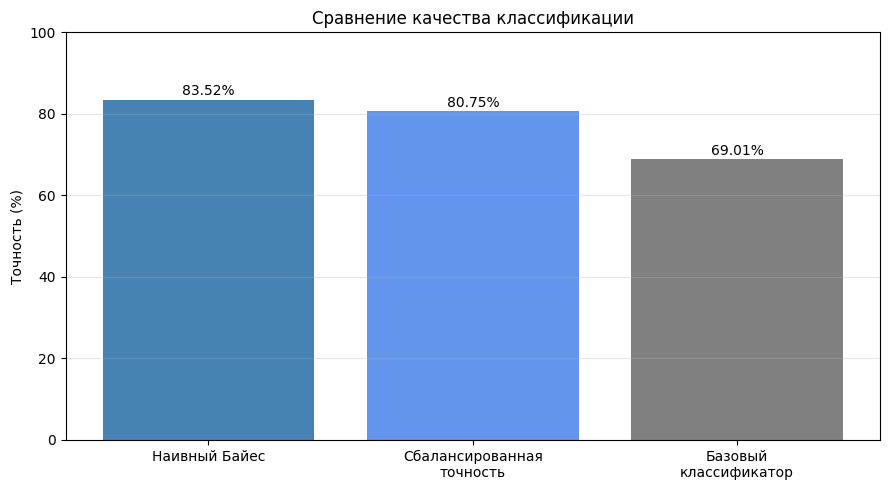

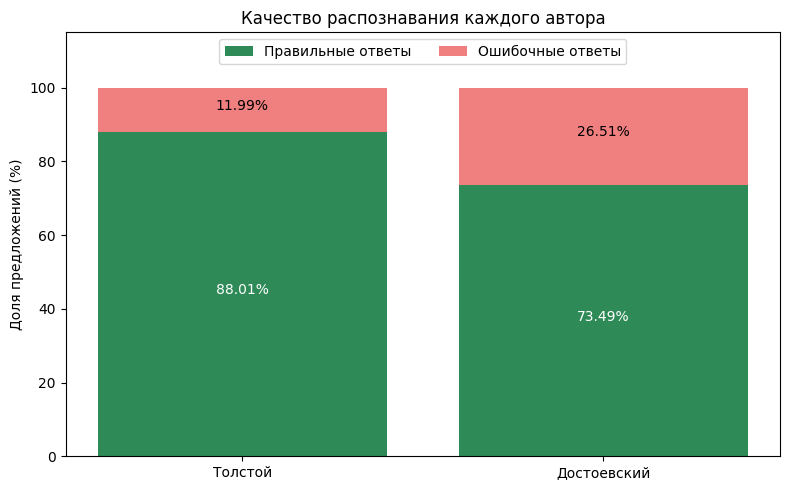

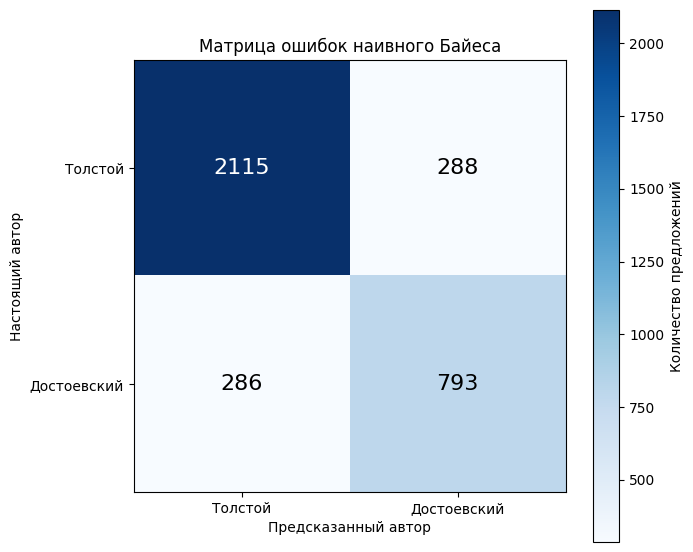

Все три графика успешно сохранены
nb_accuracy.png - 61182 байт
nb_author_accuracy.png - 65658 байт
nb_confusion_matrix.png - 80186 байт


In [38]:
# Бонус №3. Визуализация результатов

import matplotlib.pyplot as plt

BONUS_DIR.mkdir(parents=True, exist_ok=True)

# График 1. Сравнение точности

labels = [
    "Наивный Байес",
    "Сбалансированная\nточность",
    "Базовый\nклассификатор"
]

values = [
    nb_accuracy * 100,
    nb_balanced_accuracy * 100,
    nb_baseline_accuracy * 100
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    labels,
    values,
    color=["steelblue", "cornflowerblue", "gray"]
)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.title("Сравнение качества классификации")
plt.ylabel("Точность (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    BONUS_DIR / "nb_accuracy.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

# График 2. Распознавание каждого автора

correct_percent = [
    nb_author_stats[author]["accuracy"] * 100
    for author in nb_authors
]

incorrect_percent = [
    100 - value
    for value in correct_percent
]

plt.figure(figsize=(8, 5))

plt.bar(
    nb_authors,
    correct_percent,
    color="seagreen",
    label="Правильные ответы"
)

plt.bar(
    nb_authors,
    incorrect_percent,
    bottom=correct_percent,
    color="lightcoral",
    label="Ошибочные ответы"
)

for i, value in enumerate(correct_percent):

    plt.text(
        i, value / 2,
        f"{value:.2f}%",
        ha="center",
        color="white"
    )

    plt.text(
        i, value + incorrect_percent[i] / 2,
        f"{incorrect_percent[i]:.2f}%",
        ha="center"
    )

plt.title("Качество распознавания каждого автора")
plt.ylabel("Доля предложений (%)")
plt.ylim(0, 115)
plt.legend(loc="upper center", ncol=2)
plt.tight_layout()

plt.savefig(
    BONUS_DIR / "nb_author_accuracy.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

# График 3. Матрица ошибок

matrix = [
    [
        nb_confusion_matrix[true_author][predicted_author]
        for predicted_author in nb_authors
    ]
    for true_author in nb_authors
]

plt.figure(figsize=(7, 6))

plt.imshow(matrix, cmap="Blues")
plt.colorbar(label="Количество предложений")

plt.xticks(range(len(nb_authors)), nb_authors)
plt.yticks(range(len(nb_authors)), nb_authors)

plt.xlabel("Предсказанный автор")
plt.ylabel("Настоящий автор")
plt.title("Матрица ошибок наивного Байеса")

max_value = max(max(row) for row in matrix)

for i in range(len(nb_authors)):
    for j in range(len(nb_authors)):

        value = matrix[i][j]

        plt.text(
            j, i, str(value),
            ha="center",
            va="center",
            fontsize=16,
            color="white" if value > max_value / 2
            else "black"
        )

plt.tight_layout()

plt.savefig(
    BONUS_DIR / "nb_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Проверка сохранённых файлов

print("Все три графика успешно сохранены")

for path in sorted(BONUS_DIR.glob("nb_*.png")):
    print(path.name, "-", path.stat().st_size, "байт")

Сохранение результатов третьего бонуса в JSON.

In [39]:
# Бонус №3. Сохранение результатов наивного Байеса
import json
nb_results = {

    # Информация о корпусах
    "corpora": {
        "Толстой": {
            "work": "Война и мир",
            "url": CORPUS_URL,
            "sentences": len(tolstoy_sentences),
            "train_sentences": len(tolstoy_train),
            "val_sentences": len(tolstoy_val),
            "train_words": tolstoy_total_words,
            "vocab_size": len(tolstoy_vocab),
            "top20": tolstoy_word_counts.most_common(20)
        },

        "Достоевский": {
            "work": "Преступление и наказание",
            "url": DOSTOEVSKY_URL,
            "sentences": len(dostoevsky_sentences),
            "train_sentences": len(dostoevsky_train),
            "val_sentences": len(dostoevsky_val),
            "train_words": dostoevsky_total_words,
            "vocab_size": len(dostoevsky_vocab),
            "top20": dostoevsky_word_counts.most_common(20)
        }
    },

    # Параметры классификатора
    "model": {
        "type": "Multinomial Naive Bayes",
        "alpha": nb_model.alpha,
        "priors": nb_model.priors,
        "vocab_size": nb_model.vocab_size,
        "min_sentence_words": 5,
        "train_ratio": 0.9,
        "validation_ratio": 0.1,
        "unknown_words": "ignored",
        "seed": 42
    },

    # Сравнение словарей
    "vocabulary": {
        "total": len(nb_vocab),
        "common": len(common_words),
        "only_tolstoy": len(only_tolstoy),
        "only_dostoevsky": len(only_dostoevsky)
    },

    # Результаты классификации
    "metrics": {
        "total": nb_total,
        "correct": nb_correct,
        "incorrect": nb_incorrect,
        "accuracy": nb_accuracy,
        "balanced_accuracy": nb_balanced_accuracy,
        "baseline_accuracy": nb_baseline_accuracy,
        "improvement_percentage_points": (
            nb_accuracy - nb_baseline_accuracy
        ) * 100
    },

    # Статистика по каждому автору
    "author_stats": nb_author_stats,

    # Матрица ошибок
    "confusion_matrix": nb_confusion_matrix,

    # Примеры правильных и ошибочных ответов
    "examples": nb_examples,

    # Сохранённые графики
    "plots": [
        path.name
        for path in sorted(BONUS_DIR.glob("nb_*.png"))
    ]
}

# Путь к итоговому файлу
nb_results_path = BONUS_DIR / "naive_bayes.json"

# Сохранение JSON
with nb_results_path.open("w", encoding="utf-8") as f:
    json.dump(
        nb_results,
        f,
        ensure_ascii=False,
        indent=2
    )

# Проверка сохранённого файла
with nb_results_path.open("r", encoding="utf-8") as f:
    saved_nb_results = json.load(f)

print("Бонус №3 успешно сохранён")

print("Путь:", nb_results_path)
print("Размер файла:",
      nb_results_path.stat().st_size, "байт")

print("\nСохранённые метрики:")

print(json.dumps(
    saved_nb_results["metrics"],
    ensure_ascii=False,
    indent=2
))

print("\nКоличество сохранённых примеров:",
      len(saved_nb_results["examples"]))

print("Количество сохранённых графиков:",
      len(saved_nb_results["plots"]))

print("\nПроверка сохранённой точности:",
      saved_nb_results["metrics"]["accuracy"]
      == nb_accuracy)

print("Проверка матрицы ошибок:",
      saved_nb_results["confusion_matrix"]
      == nb_confusion_matrix)

print("\nВсе файлы бонусных заданий:")

for path in sorted(BONUS_DIR.iterdir()):
    print(path.name, "-", path.stat().st_size, "байт")

print("\nВсего файлов:",
      len(list(BONUS_DIR.iterdir())))

Бонус №3 успешно сохранён
Путь: /content/tgo-course/pt01/bonus/naive_bayes.json
Размер файла: 9564 байт

Сохранённые метрики:
{
  "total": 3482,
  "correct": 2908,
  "incorrect": 574,
  "accuracy": 0.8351522113727743,
  "balanced_accuracy": 0.8075447858851135,
  "baseline_accuracy": 0.6901206203331419,
  "improvement_percentage_points": 14.503159103963236
}

Количество сохранённых примеров: 12
Количество сохранённых графиков: 3

Проверка сохранённой точности: True
Проверка матрицы ошибок: True

Все файлы бонусных заданий:
bpe_comparison.json - 232538 байт
bpe_compression.png - 86415 байт
bpe_tokens_per_word.png - 86309 байт
bpe_vocab_size.png - 82167 байт
bpe_whole_words.png - 74560 байт
naive_bayes.json - 9564 байт
nb_accuracy.png - 61182 байт
nb_author_accuracy.png - 65658 байт
nb_confusion_matrix.png - 80186 байт
trigram.json - 4997 байт

Всего файлов: 10


Создание самостоятельного файла bonus.py

In [40]:
import ast
from pathlib import Path

history = get_ipython().history_manager.input_hist_raw

print("История выполнения ячеек:")
print("=" * 60)

for number in range(5, min(40, len(history))):

    source = history[number]

    lines = [
        line.strip()
        for line in source.splitlines()
        if line.strip()
    ]

    print(f"\nЯчейка №{number}")

    for line in lines[:5]:
        print(line)

    print("Количество строк:", len(source.splitlines()))

    print("-" * 60)

# Проверка функций основного файла

run_path = Path("/content/tgo-course/pt01/run.py")

run_source = run_path.read_text(encoding="utf-8")

run_tree = ast.parse(run_source)

print("\nФункции и классы в run.py:")

for node in run_tree.body:

    if isinstance(node, (ast.FunctionDef, ast.ClassDef)):
        print(node.name)

print("\nОсновной файл run.py доступен:", run_path.exists())
print("История ячеек успешно прочитана")

История выполнения ячеек:

Ячейка №5
from pathlib import Path
from urllib.request import urlretrieve
# Ссылка на корпус из методички
CORPUS_URL = (
"https://raw.githubusercontent.com/nevmenandr/"
Количество строк: 19
------------------------------------------------------------

Ячейка №6
import re
from collections import Counter
# Чтение текста романа
text = CORPUS.read_text(encoding="utf-8")
# Приведение текста к нижнему регистру
Количество строк: 27
------------------------------------------------------------

Ячейка №7
# Подсчёт частоты слов обучающей выборки
train_counts = Counter(train_words)
# Подсчёт частоты пар соседних слов
bigram_counts = Counter(
zip(train_words, train_words[1:])
Количество строк: 20
------------------------------------------------------------

Ячейка №8
import math
import random
from collections import Counter, defaultdict
class BigramModel:
# Инициализация модели
Количество строк: 89
------------------------------------------------------------

Ячейка №9
#

In [41]:
# Подготовка исходного кода для bonus.py
import ast
history = get_ipython().history_manager.input_hist_raw

# Ячейки основной части и бонусных заданий
cell_numbers = list(range(5, 16)) + list(range(20, 35))

print("Список ячеек для сборки программы")
print("=" * 60)

for number in cell_numbers:

    source = history[number]

    lines = [
        line.strip()
        for line in source.splitlines()
        if line.strip()
    ]

    print(f"\nЯчейка №{number}:")
    print(lines[0] if lines else "Пустая ячейка")

    try:
        tree = ast.parse(source)

        for node in tree.body:

            if isinstance(node, ast.ClassDef):
                print("  Класс:", node.name)

            elif isinstance(node, ast.FunctionDef):
                print("  Функция:", node.name)

    except SyntaxError:
        print("  Содержит команды Google Colab")

    # Проверяем пути к файлам
    for line in lines:
        if any(marker in line for marker in [
            "/content/",
            "Path(",
            "BONUS_DIR =",
            "CORPUS_URL =",
            "DOSTOEVSKY_URL ="
        ]):
            print("  ", line)

print("\n" + "=" * 60)
print("Проверка завершена")

Список ячеек для сборки программы

Ячейка №5:
from pathlib import Path
   CORPUS_URL = (
   LAB_DIR = Path("/content/tgo-course/pt01")

Ячейка №6:
import re

Ячейка №7:
# Подсчёт частоты слов обучающей выборки

Ячейка №8:
import math
  Класс: BigramModel

Ячейка №9:
# Температуры для эксперимента

Ячейка №10:
# Устанавливаем коэффициент сглаживания

Ячейка №11:
# Функция расчёта перплексии
  Функция: calculate_perplexity

Ячейка №12:
import json

Ячейка №13:
import time
  Функция: merge_pair
  Функция: train_bpe

Ячейка №14:
# Создаём словарь рангов слияний
  Функция: tokenize_bpe

Ячейка №15:
# Формирование результатов токенизатора BPE

Ячейка №20:
# Подсчёт частоты троек соседних слов

Ячейка №21:
# Триграммная языковая модель с откатом
  Класс: TrigramModel

Ячейка №22:
# Одинаковый коэффициент сглаживания

Ячейка №23:
def generate_with_context(language_model, start,
  Функция: generate_with_context

Ячейка №24:
# Дополнительный эксперимент с низкой температурой

Ячейка №25:
# Бонус

In [42]:
# Сборка самостоятельного файла bonus.py

import ast
import textwrap
import hashlib
from pathlib import Path

# История выполненных ячеек
history = get_ipython().history_manager.input_hist_raw

LAB_DIR = Path("/content/tgo-course/pt01")
run_path = LAB_DIR / "run.py"
bonus_path = LAB_DIR / "bonus.py"

# Контрольная сумма основного файла
run_hash_before = hashlib.sha256(
    run_path.read_bytes()
).hexdigest()

# Ячейки для сборки программы
cell_numbers = (
    list(range(5, 16))
    + list(range(20, 40))
)


# Замена путей в исходном коде
def replace_assignment(source, name, expression):

    tree = ast.parse(source)
    lines = source.splitlines(keepends=True)

    for node in tree.body:

        if isinstance(node, ast.Assign):

            for target in node.targets:

                if isinstance(target, ast.Name):
                    if target.id == name:

                        lines[
                            node.lineno - 1:node.end_lineno
                        ] = [
                            f"{name} = {expression}\n"
                        ]

                        return "".join(lines)

    raise ValueError(
        f"Переменная {name} не найдена"
    )


# Сборка исходного кода ячеек
code_parts = []

for number in cell_numbers:

    source = history[number]

    # Заменяем путь к рабочей папке
    if number == 5:

        source = replace_assignment(
            source,
            "LAB_DIR",
            "LAB_WORK_DIR"
        )

    # Заменяем путь ко второму корпусу
    if number == 31:

        source = replace_assignment(
            source,
            "DOSTOEVSKY_CORPUS",
            'LAB_WORK_DIR / "corpus_dostoevsky.txt"'
        )

    # Проверяем синтаксис каждой ячейки
    ast.parse(source)

    # Проверяем отсутствие путей Colab
    if "/content/" in source:
        raise ValueError(
            f"В ячейке {number} остался путь Colab"
        )

    code_parts.append(
        f"# Исходная ячейка №{number}\n\n"
        + source
    )


# Объединяем исходный код
experiments_code = "\n\n".join(code_parts)


# Начальная часть самостоятельной программы
header = '''
"""Лабораторная работа №1.
Дополнительные задания.

Бонус 1. Триграммная языковая модель.
Бонус 2. Исследование размера словаря BPE.
Бонус 3. Наивный байесовский классификатор.
"""

import argparse
import shutil
import tempfile
from pathlib import Path

import matplotlib

matplotlib.use("Agg")


if __name__ == "__main__":

    SCRIPT_DIR = Path(__file__).resolve().parent

    parser = argparse.ArgumentParser(
        description="Бонусные задания лабораторной №1"
    )

    parser.add_argument(
        "--output-dir",
        type=Path,
        default=SCRIPT_DIR / "bonus"
    )

    args = parser.parse_args()

    OUTPUT_DIR = args.output_dir.resolve()

    with tempfile.TemporaryDirectory(
        prefix="pt01_bonus_"
    ) as temp_dir:

        LAB_WORK_DIR = Path(temp_dir)

        # Используем уже скачанный корпус,
        # если он доступен
        existing_corpus = SCRIPT_DIR / "corpus.txt"

        if existing_corpus.exists():

            shutil.copy2(
                existing_corpus,
                LAB_WORK_DIR / "corpus.txt"
            )

'''

# Заключительная часть программы
footer = '''

        # Проверяем наличие результатов
        expected_files = [
            "trigram.json",
            "bpe_comparison.json",
            "bpe_compression.png",
            "bpe_tokens_per_word.png",
            "bpe_vocab_size.png",
            "bpe_whole_words.png",
            "naive_bayes.json",
            "nb_accuracy.png",
            "nb_author_accuracy.png",
            "nb_confusion_matrix.png"
        ]

        for filename in expected_files:

            if not (BONUS_DIR / filename).is_file():

                raise FileNotFoundError(filename)

        # Сохраняем итоговые результаты
        OUTPUT_DIR.mkdir(
            parents=True,
            exist_ok=True
        )

        for filename in expected_files:

            shutil.copy2(
                BONUS_DIR / filename,
                OUTPUT_DIR / filename
            )

        print("\\nВсе бонусные задания выполнены")
        print("Результаты сохранены в:", OUTPUT_DIR)
        print("Количество файлов:", len(expected_files))

'''

# Формирование полного исходного кода
bonus_full_code = (
    header
    + textwrap.indent(experiments_code, " " * 8)
    + footer
)

# Проверка синтаксиса всей программы
compile(
    bonus_full_code,
    str(bonus_path),
    "exec"
)

# Сохранение файла
bonus_path.write_text(
    bonus_full_code,
    encoding="utf-8"
)

# Повторная проверка основного файла
run_hash_after = hashlib.sha256(
    run_path.read_bytes()
).hexdigest()

# Вывод результатов
print("Файл bonus.py успешно создан")
print("Синтаксис проверен")

print("\nПуть:", bonus_path)

print("Размер файла:",
      bonus_path.stat().st_size, "байт")

print("Количество строк:",
      len(bonus_full_code.splitlines()))

print("Количество использованных ячеек:",
      len(cell_numbers))

print("\nОтсутствие абсолютных путей Colab:",
      "/content/" not in bonus_full_code)

print("Основной файл run.py не изменён:",
      run_hash_before == run_hash_after)

print("\nСборка программы завершена")

Файл bonus.py успешно создан
Синтаксис проверен

Путь: /content/tgo-course/pt01/bonus.py
Размер файла: 84130 байт
Количество строк: 2479
Количество использованных ячеек: 31

Отсутствие абсолютных путей Colab: True
Основной файл run.py не изменён: True

Сборка программы завершена


In [43]:
# Проверка самостоятельного запуска bonus.py

import subprocess
import sys
import time
import hashlib
import tempfile
from pathlib import Path

LAB_DIR = Path("/content/tgo-course/pt01")

bonus_path = LAB_DIR / "bonus.py"
run_path = LAB_DIR / "run.py"

# Создаём отдельную папку для проверки
CHECK_DIR = Path(tempfile.mkdtemp(
    prefix="pt01_bonus_check_",
    dir="/content"
))

# Контрольные суммы исходных файлов
protected_files = (
    [run_path]
    + list((LAB_DIR / "artifacts").glob("*.json"))
    + list((LAB_DIR / "bonus").glob("*"))
)

hashes_before = {
    path: hashlib.sha256(path.read_bytes()).hexdigest()
    for path in protected_files
    if path.is_file()
}

print("Запуск самостоятельной программы bonus.py")
print("Папка проверки:", CHECK_DIR)
print("Выполняются все три бонусных задания...", flush=True)

start_time = time.perf_counter()

# Запуск в отдельном процессе Python
result = subprocess.run(
    [
        sys.executable,
        "-u",
        str(bonus_path),
        "--output-dir",
        str(CHECK_DIR)
    ],
    cwd="/content",
    capture_output=True,
    text=True,
    encoding="utf-8"
)

elapsed_time = time.perf_counter() - start_time

# Сохраняем полный журнал выполнения
log_path = CHECK_DIR.parent / (
    CHECK_DIR.name + ".log"
)

log_path.write_text(
    result.stdout + "\n" + result.stderr,
    encoding="utf-8"
)

# Выводим заключительную часть журнала
print("\nРезультат выполнения:")
print("\n".join(result.stdout.splitlines()[-30:]))

if result.stderr:
    print("\nДополнительные сообщения:")
    print(result.stderr[-4000:])

print("\nКод завершения:", result.returncode)
print("Время выполнения:", round(elapsed_time, 2), "секунд")

# Ожидаемые результаты
expected_files = [
    "trigram.json",
    "bpe_comparison.json",
    "bpe_compression.png",
    "bpe_tokens_per_word.png",
    "bpe_vocab_size.png",
    "bpe_whole_words.png",
    "naive_bayes.json",
    "nb_accuracy.png",
    "nb_author_accuracy.png",
    "nb_confusion_matrix.png"
]

print("\nПроверка созданных файлов:")

for filename in expected_files:

    path = CHECK_DIR / filename

    if path.is_file():
        print(filename, "-", path.stat().st_size, "байт")
    else:
        print(filename, "- НЕ НАЙДЕН")

# Проверка сохранности исходных файлов
originals_unchanged = all(
    path.is_file()
    and hashlib.sha256(path.read_bytes()).hexdigest() == old_hash
    for path, old_hash in hashes_before.items()
)

all_files_created = all(
    (CHECK_DIR / filename).is_file()
    and (CHECK_DIR / filename).stat().st_size > 0
    for filename in expected_files
)

print("\nИтоговая проверка:")

print("Программа завершилась успешно:",
      result.returncode == 0)

print("Все 10 файлов созданы:",
      all_files_created)

print("Исходные файлы не изменены:",
      originals_unchanged)

print("Полный журнал:", log_path)

Запуск самостоятельной программы bonus.py
Папка проверки: /content/pt01_bonus_check_1ys53o5a
Выполняются все три бонусных задания...

Результат выполнения:
  "incorrect": 574,
  "accuracy": 0.8351522113727743,
  "balanced_accuracy": 0.8075447858851135,
  "baseline_accuracy": 0.6901206203331419,
  "improvement_percentage_points": 14.503159103963236
}

Количество сохранённых примеров: 12
Количество сохранённых графиков: 3

Проверка сохранённой точности: True
Проверка матрицы ошибок: True

Все файлы бонусных заданий:
bpe_comparison.json - 232537 байт
bpe_compression.png - 86415 байт
bpe_tokens_per_word.png - 86309 байт
bpe_vocab_size.png - 82167 байт
bpe_whole_words.png - 74560 байт
naive_bayes.json - 9564 байт
nb_accuracy.png - 61182 байт
nb_author_accuracy.png - 65658 байт
nb_confusion_matrix.png - 80186 байт
trigram.json - 4997 байт

Всего файлов: 10

Все бонусные задания выполнены
Результаты сохранены в: /content/pt01_bonus_check_1ys53o5a
Количество файлов: 10

Код завершения: 0
Время

Проверка воспроизводимости бонусных заданий.

In [44]:
import json
import hashlib
from pathlib import Path

# Папка первоначальных результатов
ORIGINAL_BONUS_DIR = Path(
    "/content/tgo-course/pt01/bonus"
)

# Сравнение JSON-файлов
def compare_json(first, second, path=""):

    differences = []

    if isinstance(first, dict) and isinstance(second, dict):

        keys = sorted(set(first) | set(second))

        for key in keys:

            current_path = f"{path}.{key}" if path else key

            if key not in first or key not in second:

                differences.append(
                    (current_path, first.get(key), second.get(key))
                )

            else:

                differences.extend(
                    compare_json(
                        first[key],
                        second[key],
                        current_path
                    )
                )

    elif isinstance(first, list) and isinstance(second, list):

        if len(first) != len(second):

            differences.append(
                (path + ".length", len(first), len(second))
            )

        for i, (a, b) in enumerate(zip(first, second)):

            differences.extend(
                compare_json(a, b, f"{path}[{i}]")
            )

    elif first != second:

        differences.append((path, first, second))

    return differences

# Проверяем три JSON-файла
json_files = [
    "trigram.json",
    "bpe_comparison.json",
    "naive_bayes.json"
]

bonus_differences = {}

print("ПРОВЕРКА ВОСПРОИЗВОДИМОСТИ")
print("=" * 60)

for filename in json_files:

    original = json.loads(
        (ORIGINAL_BONUS_DIR / filename).read_text(
            encoding="utf-8"
        )
    )

    repeated = json.loads(
        (CHECK_DIR / filename).read_text(
            encoding="utf-8"
        )
    )

    differences = compare_json(original, repeated)

    bonus_differences[filename] = differences

    print("\nФайл:", filename)

    print("Полное совпадение:", not differences)
    print("Количество различий:", len(differences))

    for field, first, second in differences[:20]:

        print("\nПоле:", field)
        print("Первоначальный результат:", first)
        print("Повторный результат:", second)

    print("-" * 60)

# Проверка графиков по контрольным суммам SHA-256

print("\nСРАВНЕНИЕ ГРАФИКОВ")
print("=" * 60)

plot_checks = {}

for path in sorted(ORIGINAL_BONUS_DIR.glob("*.png")):

    repeated_path = CHECK_DIR / path.name

    original_hash = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    repeated_hash = hashlib.sha256(
        repeated_path.read_bytes()
    ).hexdigest()

    plot_checks[path.name] = (
        original_hash == repeated_hash
    )

    print(path.name, ":", plot_checks[path.name])

# Итоги проверки

print("\nИТОГИ ПРОВЕРКИ")
print("=" * 60)

print("Проверено JSON-файлов:", len(json_files))

print("Проверено графиков:", len(plot_checks))

print("Совпадающих графиков:",
      sum(plot_checks.values()))

print("Все графики идентичны:",
      all(plot_checks.values()))

print("Всего различий в JSON:",
      sum(len(d) for d in bonus_differences.values()))

print("\nПроверка завершена")

ПРОВЕРКА ВОСПРОИЗВОДИМОСТИ

Файл: trigram.json
Полное совпадение: True
Количество различий: 0
------------------------------------------------------------

Файл: bpe_comparison.json
Полное совпадение: False
Количество различий: 1

Поле: training_time_seconds
Первоначальный результат: 175.44771963800122
Повторный результат: 178.6490711639999
------------------------------------------------------------

Файл: naive_bayes.json
Полное совпадение: True
Количество различий: 0
------------------------------------------------------------

СРАВНЕНИЕ ГРАФИКОВ
bpe_compression.png : True
bpe_tokens_per_word.png : True
bpe_vocab_size.png : True
bpe_whole_words.png : True
nb_accuracy.png : True
nb_author_accuracy.png : True
nb_confusion_matrix.png : True

ИТОГИ ПРОВЕРКИ
Проверено JSON-файлов: 3
Проверено графиков: 7
Совпадающих графиков: 7
Все графики идентичны: True
Всего различий в JSON: 1

Проверка завершена


Заключительная проверка обязательной части.

In [45]:
import json
import subprocess
import sys
from pathlib import Path

LAB_DIR = Path("/content/tgo-course/pt01")
ARTIFACTS = LAB_DIR / "artifacts"
BONUS_DIR = LAB_DIR / "bonus"

# Чтение обязательных артефактов
bigram_data = json.loads(
    (ARTIFACTS / "bigram.json").read_text(
        encoding="utf-8"
    )
)

bpe_data = json.loads(
    (ARTIFACTS / "bpe.json").read_text(
        encoding="utf-8"
    )
)

print("ЗАКЛЮЧИТЕЛЬНАЯ ПРОВЕРКА")
print("=" * 60)

print("\nОбязательная часть:")

print("Всего слов:", bigram_data["words"])
print("Обучающих слов:", bigram_data["train_words"])
print("Проверочных слов:", bigram_data["val_words"])

print("\nПерплексия:")

for alpha, value in bigram_data["perplexity"].items():
    print(f"alpha = {alpha}: {value:.4f}")

print("\nКоличество слияний BPE:",
      bpe_data["num_merges"])

print("Размер словаря BPE:",
      bpe_data["vocab_size"])

print("Токенов на слово:",
      round(bpe_data["stats"]["tokens_per_word"], 4))

print("\nАртефакты полного режима:",
      bpe_data["num_merges"] >= 1500)

# Проверка файлов программы
print("\nФайлы программы:")

for filename in ["run.py", "bonus.py"]:

    path = LAB_DIR / filename

    print(filename, "- существует:", path.is_file())

    compile(
        path.read_text(encoding="utf-8"),
        str(path),
        "exec"
    )

    print("Синтаксис корректен: True")

# Проверка бонусных результатов
print("\nБонусные задания:")

print("Количество JSON-файлов:",
      len(list(BONUS_DIR.glob("*.json"))))

print("Количество графиков:",
      len(list(BONUS_DIR.glob("*.png"))))

# Запуск обязательных автотестов
print("\nЗАПУСК АВТОТЕСТОВ")
print("=" * 60)

test_result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "tests/test_pt01.py",
        "-v"
    ],
    cwd=LAB_DIR.parent,
    capture_output=True,
    text=True
)

print(test_result.stdout)

if test_result.stderr:
    print(test_result.stderr)

print("\nВсе автотесты пройдены:",
      test_result.returncode == 0)

print("Код завершения:",
      test_result.returncode)

ЗАКЛЮЧИТЕЛЬНАЯ ПРОВЕРКА

Обязательная часть:
Всего слов: 433082
Обучающих слов: 389773
Проверочных слов: 43309

Перплексия:
alpha = 1: 15748.1131
alpha = 0.1: 7743.5441
alpha = 0.01: 5309.6357

Количество слияний BPE: 1500
Размер словаря BPE: 1534
Токенов на слово: 1.9327

Артефакты полного режима: True

Файлы программы:
run.py - существует: True
Синтаксис корректен: True
bonus.py - существует: True
Синтаксис корректен: True

Бонусные задания:
Количество JSON-файлов: 3
Количество графиков: 7

ЗАПУСК АВТОТЕСТОВ
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/tgo-course
configfile: pytest.ini
plugins: anyio-4.15.1, langsmith-0.14.12, platformdirs-4.13.5, typeguard-4.6.0
collecting ... collected 8 items

tests/test_pt01.py::test_split PASSED                                    [ 12%]
tests/test_pt01.py::test_top20 PASSED                

Загрузка файла README.md

In [46]:
from google.colab import files
from pathlib import Path

# Загружаем файл с ноутбука
uploaded = files.upload()

# Путь сохранения отчёта
LAB_DIR = Path("/content/tgo-course/pt01")
readme_path = LAB_DIR / "README.md"

# Сохраняем отчёт
if len(uploaded) != 1:
    raise ValueError("Выберите только один файл README.md")

readme_path.write_bytes(next(iter(uploaded.values())))

print("\nОтчёт README.md успешно сохранён")
print("Путь:", readme_path)
print("Размер файла:", readme_path.stat().st_size, "байт")
print("Файл существует:", readme_path.is_file())

Saving README.md to README (1).md

Отчёт README.md успешно сохранён
Путь: /content/tgo-course/pt01/README.md
Размер файла: 10599 байт
Файл существует: True


In [47]:
# Просмотр итогового отчёта

from IPython.display import display, Markdown

display(
    Markdown(
        readme_path.read_text(encoding="utf-8")
    )
)

# Лабораторная работа №1. Языковая модель из счётчиков и свой токенизатор

Заочное отделение, группа МТИ2532. Выполнила: Попова.

## 1. Что сделано

- Подготовила корпус романа Л. Н. Толстого «Война и мир»: привела текст к нижнему регистру, заменила «ё» на «е», выделила слова и отложила последние 10% для проверки.
- Реализовала биграммную модель со сглаживанием Лапласа, генерацию по 30 слов при температурах 0.5, 1 и 2 с фиксированным seed, расчёт логарифма правдоподобия и перплексии.
- Реализовала собственный BPE с маркером конца слова `</w>` и применением слияний по их рангам: 200 слияний в быстром режиме и 1500 в полном.
- Выполнила все три бонусных задания: триграммная модель с откатом на биграммы, сравнение размеров словаря BPE и классификация предложений наивным Байесом.

Работу выполняла в Google Colab (Python 3.13.18). Для основной части не использовала готовые языковые модели и токенизаторы. Для бонусных графиков использовала `matplotlib`.

Команды запуска из корня репозитория:

```bash
python pt01/run.py --fast && python -m pytest tests/test_pt01.py
python pt01/run.py
python pt01/bonus.py
```

Для запуска бонусов необходим `matplotlib`.

## 2. Что получилось

**Корпус.** Всего 433 082 слова, из них 389 773 обучающих и 43 309 проверочных. Размер словаря всего корпуса — 48 117, обучающей части — 45 309. В обучающей части 236 820 уникальных биграмм.

**20 самых частых слов корпуса:** и (21085), в (10870), не (8520), что (7600), он (7395), на (6665), с (5861), как (4011), его (3895), к (3428), я (2854), она (2732), но (2725), все (2674), было (2501), это (2434), то (2261), сказал (2000), так (1954), о (1832).

**Перплексия биграммной модели:**

| α | Перплексия |
|---:|---:|
| 1 | 15748.1131 |
| 0.1 | 7743.5441 |
| 0.01 | 5309.6357 |

Из трёх проверенных значений α наилучший результат получился при 0.01. При слишком большом сглаживании распределение вероятностей становится ближе к равномерному, поэтому модель хуже учитывает частые сочетания слов.

**Примеры генерации с одинаковым стартовым словом:**

- T = 0.5: князь андрей не было он с тем чтобы не было в москве и с ним разговор и не мог удержаться чтобы в темноте ночи не говорили что он не был
- T = 2: князь быть была все молчало крестилось только помнила этот возьмет ее лоб широкими скулами красивым принялись с принятием таинства брака будь здоров и дальше несмотря ни той губернии он выразил

При низкой температуре чаще выбираются вероятные продолжения, но появляются повторы. При высокой температуре текст разнообразнее, однако связь между словами становится слабее. Все шесть образцов сохранены в [bigram.json](artifacts/bigram.json).

**Правдоподобие при α = 0.01:**

- Исходный текст: «это был георгий й степени на другой день были у фельдмаршала обед», logP = −83.1429.
- Перемешанный текст: «день на георгий были у другой обед й степени это был фельдмаршала», logP = −94.8913.

Исходный порядок слов оказался более правдоподобным. В исходном тексте 5 пар не встречались при обучении; без сглаживания их вероятности были бы нулевыми.

**BPE.** При 1500 слияниях получился словарь из 1534 токенов. Корпус содержит 2 245 342 символа и после токенизации — 836 998 токенов, в среднем 1.9327 токена на слово. Коэффициент сжатия относительно числа символов — 2.6826. Время обучения в полном режиме — 63.37 с.

| Слово | Токены |
|---|---|
| наполеон | `наполеон</w>` |
| сказала | `сказала</w>` |
| неудовольствие | `не`, `удоволь`, `ствие</w>` |

Список слияний и статистика сохранены в [bpe.json](artifacts/bpe.json).

**Бонус №1 — триграммы.** При сравнении на одинаковых 43 307 словах перплексия биграммной модели составила 5310.2781, триграммной — 4946.6562 (снижение на 6.85%). Использовала дисконтирование D = 0.75. Доля ранее не встречавшихся триграмм — 88.58%. При T = 0.5 в примерах триграммной генерации получились более связные локальные сочетания. [Результаты и примеры генерации](bonus/trigram.json).

**Бонус №2 — размер словаря BPE.**

| Слияний | Размер словаря | Токенов на слово | Сжатие | Словоупотреблений одним токеном, % |
|---:|---:|---:|---:|---:|
| 300 | 334 | 2.8646 | 1.8099 | 34.17 |
| 1500 | 1534 | 1.9327 | 2.6826 | 55.94 |
| 5000 | 5034 | 1.4898 | 3.4801 | 73.01 |

Сравнила разбиение 12 слов. Например, «неудовольствие» при 300, 1500 и 5000 слияниях разбивается на 8, 3 и 2 токена соответственно. Единой границы по частоте между целым словом и подсловами нет: результат зависит также от частот его составляющих. [Результаты](bonus/bpe_comparison.json), графики: [токенов на слово](bonus/bpe_tokens_per_word.png), [сжатие](bonus/bpe_compression.png), [словарь](bonus/bpe_vocab_size.png), [целые слова](bonus/bpe_whole_words.png).

**Бонус №3 — наивный Байес.** Сравнила «Войну и мир» и «Преступление и наказание» Ф. М. Достоевского. При α = 1 и равных априорных вероятностях авторов правильно классифицировано 2908 из 3482 отложенных предложений. Точность — 83.52%, сбалансированная точность — 80.75%, базовая точность при выборе наиболее частого класса — 69.01%. Преимущество над базовым методом — 14.50 процентного пункта.

| Настоящий автор / Предсказанный | Толстой | Достоевский |
|---|---:|---:|
| Толстой | 2115 | 288 |
| Достоевский | 286 | 793 |

[Результаты](bonus/naive_bayes.json), графики: [общая точность](bonus/nb_accuracy.png), [точность по авторам](bonus/nb_author_accuracy.png), [матрица ошибок](bonus/nb_confusion_matrix.png).

**Проверка.** В быстром и полном режимах, а также при заключительной проверке в Colab пройдены все 8 автотестов (`8 passed`). При самостоятельном запуске `bonus.py` получены все 10 бонусных файлов. Содержимое трёх JSON совпало, кроме времени обучения BPE, все 7 графиков побайтово совпали по SHA-256.

## 3. Что не получилось и почему

Биграммная модель не генерирует полностью связный текст, поскольку учитывает только одно предыдущее слово. Триграммы улучшили перплексию, но из-за разреженности данных часто требуется откат на биграммы. Даже при 5000 слияниях некоторые редкие слова остаются разбитыми на части.

Наивный Байес допустил 574 ошибки. Возможные причины — общая лексика двух произведений и отсутствие учёта порядка слов. Полученная точность относится к этим двум книгам и не доказывает, что модель так же хорошо определяет авторство других произведений.

При сборке `run.py` в Colab возникла ошибка `OSError: source code not available`. Устранила её, используя историю выполненных ячеек. При повторном обучении BPE на 5000 слияниях время изменилось с 175.45 до 178.65 с, но результаты токенизации остались прежними.


Создание ZIP-архива.

In [48]:
# Сохранение лабораторной работы

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

LAB_DIR = Path("/content/tgo-course/pt01")

archive_path = Path(
    "/content/Лабораторная1_Попова_МТИ2532.zip"
)

# Файлы для сохранения
selected_files = [
    LAB_DIR / "run.py",
    LAB_DIR / "bonus.py",
    LAB_DIR / "README.md",
    LAB_DIR / "artifacts/bigram.json",
    LAB_DIR / "artifacts/bpe.json"
]

selected_files += sorted(
    (LAB_DIR / "bonus").glob("*.json")
)

selected_files += sorted(
    (LAB_DIR / "bonus").glob("*.png")
)

# Проверка наличия файлов
assert len(selected_files) == 15
assert all(path.is_file() for path in selected_files)

# Создание архива
with ZipFile(archive_path, "w", ZIP_DEFLATED) as archive:

    for path in selected_files:

        relative_path = path.relative_to(LAB_DIR.parent)

        archive.write(path, relative_path)

        print("Добавлен:", relative_path)

# Проверка архива
with ZipFile(archive_path, "r") as archive:

    print("\nКоличество файлов:", len(archive.namelist()))
    print("Архив исправен:", archive.testzip() is None)

print("\nАрхив успешно создан")
print("Название:", archive_path.name)
print("Размер:", archive_path.stat().st_size, "байт")

# Скачивание на ноутбук
files.download(str(archive_path))

Добавлен: pt01/run.py
Добавлен: pt01/bonus.py
Добавлен: pt01/README.md
Добавлен: pt01/artifacts/bigram.json
Добавлен: pt01/artifacts/bpe.json
Добавлен: pt01/bonus/bpe_comparison.json
Добавлен: pt01/bonus/naive_bayes.json
Добавлен: pt01/bonus/trigram.json
Добавлен: pt01/bonus/bpe_compression.png
Добавлен: pt01/bonus/bpe_tokens_per_word.png
Добавлен: pt01/bonus/bpe_vocab_size.png
Добавлен: pt01/bonus/bpe_whole_words.png
Добавлен: pt01/bonus/nb_accuracy.png
Добавлен: pt01/bonus/nb_author_accuracy.png
Добавлен: pt01/bonus/nb_confusion_matrix.png

Количество файлов: 15
Архив исправен: True

Архив успешно создан
Название: Лабораторная1_Попова_МТИ2532.zip
Размер: 509916 байт


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>